# Mini Projeto Integrador – Parte 2
## Análise Multidomínio de um Sinal e de um Sistema: **Circuito RC**

**Disciplina:** Processamento Digital de Sinais — IFPB

**Aplicação escolhida:** circuito RC passa-baixas condicionando o sinal de um sensor (ex.: monitoramento de corrente/tensão com uma componente fundamental e uma interferência de frequência mais alta).

### Ideia geral do projeto
Um mesmo circuito RC é estudado em **quatro domínios**:

| Domínio | O que vamos olhar |
|---|---|
| Tempo | formas de onda de entrada e saída do circuito |
| Frequência | FFT, espectros de magnitude e fase, aliasing e janelamento |
| Plano-s | polo de $H(s)$, estabilidade, resposta temporal |
| Plano-z | polo de $H(z)$, círculo unitário, relação $z=e^{sT_s}$ |

### Roteiro do notebook
1. Escolha da aplicação (circuito RC)
2. Geração do sinal (≥ 2 componentes de frequência)
3. Amostragem e critério de Nyquist
4. Análise espectral (FFT)
5. Aliasing
6. Janelamento (retangular × Hann × Hamming)
7. Modelo contínuo $H(s)$
8. Modelo discreto $H(z)$
9. Relação entre os planos ($z=e^{sT_s}$)
10. Discussão

### Como usar
- Execute as células **de cima para baixo** (o código de cada etapa depende das anteriores).
- Dependências: `numpy`, `scipy`, `matplotlib`, `pandas` (`pip install numpy scipy matplotlib pandas`).
- As figuras são salvas automaticamente em `../figuras/` e os dados em `../dados/`.

## 0. Configuração inicial

Aqui importamos as bibliotecas e definimos funções auxiliares usadas no notebook inteiro:

- `salvar(fig, nome)`: salva a figura na pasta `../figuras/` (resolução alta, pronta para o relatório);
- estilo padrão dos gráficos (fonte, grade, tamanho), para que **todos os gráficos tenham título, eixos com unidades, legenda e parâmetros** — como exige o roteiro.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy import signal
import pandas as pd
from pathlib import Path
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "lines.linewidth": 1.6,
})

# Pastas de saída (relativas à pasta do notebook: mini-projeto/codigo/)
FIG_DIR  = Path("../figuras")
DATA_DIR = Path("../dados")
RES_DIR  = Path("../../resultados")
for p in (FIG_DIR, DATA_DIR, RES_DIR):
    p.mkdir(parents=True, exist_ok=True)

def salvar(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")

## Etapa 1 – Escolha da aplicação: circuito RC

Escolhemos o **circuito RC passa-baixas**, muito usado como filtro de condicionamento de sinais de sensores (corrente, vibração, temperatura) antes do ADC.

A entrada $v_{in}(t)$ contém:
- uma componente **fundamental** (a informação de interesse);
- uma componente de **frequência mais alta** (interferência/harmônica) que o filtro deve atenuar.

A saída é a tensão no capacitor, $v_{out}(t)$, que será o **sinal medido** e analisado no restante do projeto.

**Modelo do circuito** (lei das malhas, com $i=C\,dv_{out}/dt$):

$$RC\frac{dv_{out}}{dt}+v_{out}=v_{in}\quad\Longrightarrow\quad H(s)=\frac{V_{out}(s)}{V_{in}(s)}=\frac{1}{\tau s+1},\qquad \tau=RC$$

- Constante de tempo: $\tau = RC$
- Frequência de corte: $f_c=\dfrac{1}{2\pi\tau}$ (onde $|H|=1/\sqrt{2}\approx -3$ dB)

Valores escolhidos: $R = 1{,}6\ \text{k}\Omega$ e $C = 1\ \mu\text{F}$.

R=1.6 kΩ, C=1 µF, τ=1.6 ms, fc=99.5 Hz


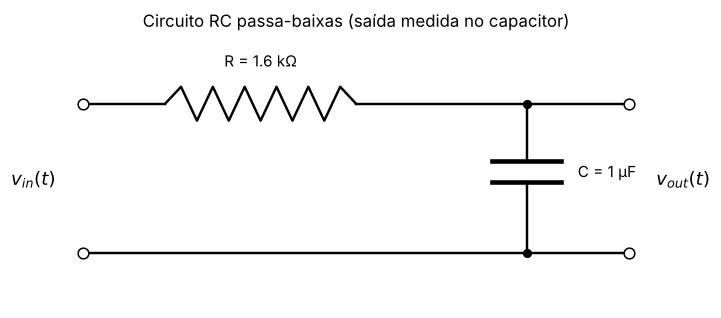

In [2]:
# ---- Parâmetros do circuito RC ----
R   = 1.6e3      # ohm
C   = 1.0e-6     # farad
tau = R * C      # constante de tempo [s]
fc  = 1 / (2*np.pi*tau)   # frequência de corte [Hz]

PARAMS_RC = f"R={R/1e3:.1f} kΩ, C={C*1e6:.0f} µF, τ={tau*1e3:.1f} ms, fc={fc:.1f} Hz"
print(PARAMS_RC)

def desenhar_circuito_rc():
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.set_xlim(0, 10); ax.set_ylim(0, 4); ax.axis("off")
    # fios
    ax.plot([1, 2.2], [3, 3], "k-"); ax.plot([5, 9], [3, 3], "k-")
    ax.plot([1, 9], [0.8, 0.8], "k-")
    ax.plot([1, 1], [0.8, 3], "k:", alpha=0)  # (apenas para limites)
    # resistor (zigue-zague)
    xs = np.linspace(2.2, 5, 13)
    ys = 3 + np.array([0,.25,-.25,.25,-.25,.25,-.25,.25,-.25,.25,-.25,.25,0])
    ax.plot(xs, ys, "k-")
    # capacitor
    ax.plot([7.5, 7.5], [3, 2.15], "k-"); ax.plot([7.5, 7.5], [1.85, 0.8], "k-")
    ax.plot([7.0, 8.0], [2.15, 2.15], "k-", lw=3); ax.plot([7.0, 8.0], [1.85, 1.85], "k-", lw=3)
    # terminais e junções
    for (x0, y0) in [(1, 3), (1, 0.8), (9, 3), (9, 0.8)]:
        ax.plot(x0, y0, "o", mfc="white", mec="k", ms=7)
    for (x0, y0) in [(7.5, 3), (7.5, 0.8)]:
        ax.plot(x0, y0, "ko", ms=5)
    # rótulos
    ax.text(3.6, 3.55, f"R = {R/1e3:.1f} kΩ", ha="center")
    ax.text(8.25, 2.0, f"C = {C*1e6:.0f} µF", ha="left", va="center")
    ax.text(0.6, 1.9, "$v_{in}(t)$", ha="right", va="center", fontsize=12)
    ax.text(9.4, 1.9, "$v_{out}(t)$", ha="left", va="center", fontsize=12)
    ax.set_title("Circuito RC passa-baixas (saída medida no capacitor)")
    return fig

fig = desenhar_circuito_rc()
salvar(fig, "01_circuito_rc")
plt.show()

## Etapa 2 – Geração do sinal

A entrada do circuito é a soma de duas senoides:

$$v_{in}(t)=A_1\cos(2\pi f_1 t+\varphi_1)+A_2\cos(2\pi f_2 t+\varphi_2)$$

Em **regime permanente senoidal**, o circuito apenas multiplica a amplitude por $|H(j2\pi f)|$ e soma $\angle H(j2\pi f)$ à fase de cada componente. Logo, o sinal de saída (o que o sensor mede) é:

$$x(t)=v_{out}(t)=\sum_{k=1}^{2}A_k\,\big|H(j2\pi f_k)\big|\cos\!\big(2\pi f_k t+\varphi_k+\angle H(j2\pi f_k)\big),\qquad H(j\omega)=\frac{1}{1+j\omega\tau}$$

**Parâmetros definidos** (amplitudes, frequências, fases e intervalo de observação):

| Componente | $A_k$ (V) | $f_k$ (Hz) | $\varphi_k$ |
|---|---|---|---|
| 1 (fundamental) | 1,0 | 50 | 0° |
| 2 (interferência) | 1,0 | 400 | 30° |

Intervalo de observação: $T_{obs}=1$ s.

> Com $f_c\approx 99{,}5$ Hz, esperamos que a componente de 50 Hz passe quase intacta e a de 400 Hz seja bastante atenuada. Para desenhar curvas "contínuas" usamos uma taxa de cálculo muito alta (50 kHz) como aproximação do tempo contínuo.

`NOISE_STD` permite adicionar ruído gaussiano de sensor (deixe `0.0` para análise limpa; experimente `0.02`).

In [3]:
# ---- Parâmetros do sinal de entrada ----
f1, f2   = 50.0, 400.0                 # Hz
A1, A2   = 1.0, 1.0                    # V
phi1, phi2 = 0.0, np.deg2rad(30.0)     # rad
T_obs    = 1.0                         # s (intervalo de observação)
NOISE_STD = 0.0                        # V (ruído do sensor; 0 = sem ruído)

def H_jw(f):
    """Resposta em frequência do RC: H(j2πf) = 1/(1 + j2πfτ)."""
    return 1 / (1 + 1j*2*np.pi*np.asarray(f)*tau)

comps_in  = [(A1, f1, phi1), (A2, f2, phi2)]
comps_out = [(A*abs(H_jw(f)), f, ph + np.angle(H_jw(f))) for (A, f, ph) in comps_in]

def gerar(comps, t):
    """Soma de cossenos: lista de (amplitude, frequência, fase)."""
    return sum(A*np.cos(2*np.pi*f*t + ph) for (A, f, ph) in comps)

# "Tempo contínuo" (aproximação com taxa muito alta)
fs_cont = 50_000
t_cont  = np.arange(0, T_obs, 1/fs_cont)
vin_c   = gerar(comps_in,  t_cont)
vout_c  = gerar(comps_out, t_cont)

# Tabela das componentes (entrada e saída)
wrap = lambda ang: np.rad2deg(np.angle(np.exp(1j*ang)))
tab_comp = pd.DataFrame({
    "f (Hz)":          [f1, f2],
    "A_in (V)":        [A1, A2],
    "φ_in (°)":        [wrap(phi1), wrap(phi2)],
    "|H(j2πf)|":       [abs(H_jw(f1)), abs(H_jw(f2))],
    "∠H (°)":          [np.rad2deg(np.angle(H_jw(f1))), np.rad2deg(np.angle(H_jw(f2)))],
    "A_out (V)":       [c[0] for c in comps_out],
    "φ_out (°)":       [wrap(c[2]) for c in comps_out],
}, index=["Componente 1", "Componente 2"])
display(tab_comp.round(4))

,f (Hz),A_in (V),φ_in (°),|H(j2πf)|,∠H (°),A_out (V),φ_out (°)
Componente 1,50.0,1.0,0.0,0.8935,-26.6866,0.8935,-26.6866
Componente 2,400.0,1.0,30.0,0.2413,-76.0350,0.2413,-46.0350


### Visualização: entrada × saída no tempo
O gráfico mostra 60 ms (3 períodos da componente de 50 Hz). Repare como a saída $x(t)$ fica **mais suave**: a componente rápida de 400 Hz foi atenuada pelo RC, enquanto a de 50 Hz praticamente se mantém. No gráfico de baixo, as duas componentes de $x(t)$ aparecem separadas (tracejado).

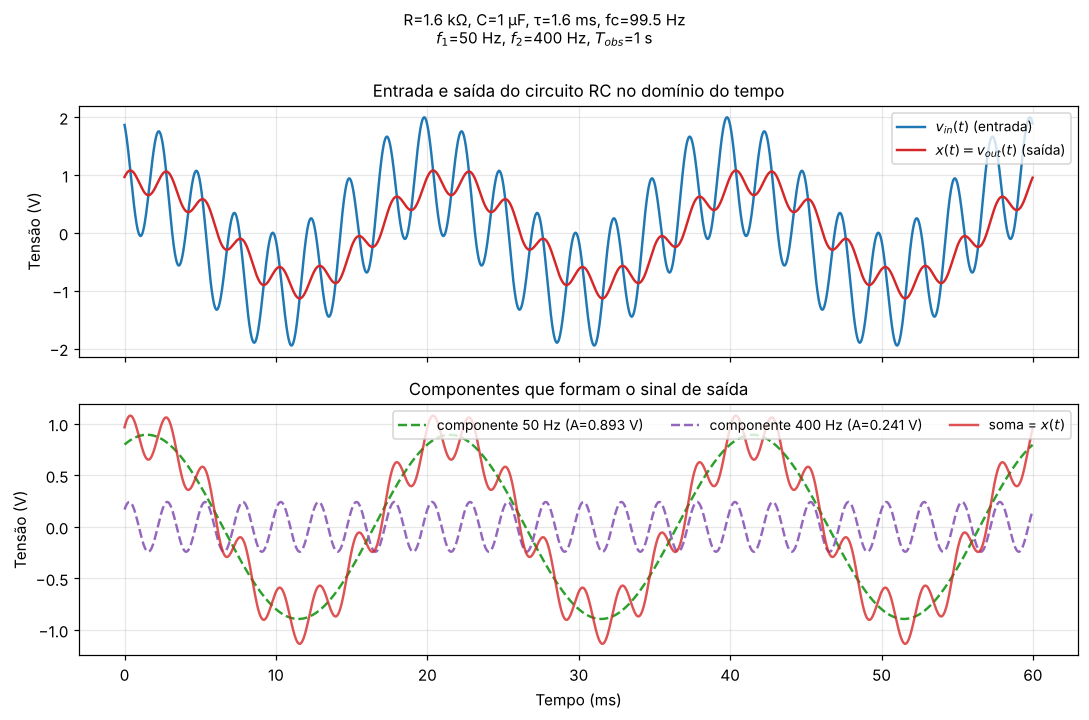

In [4]:
m = t_cont <= 0.060
t_ms = t_cont[m]*1e3

fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

axs[0].plot(t_ms, vin_c[m], color="tab:blue", label="$v_{in}(t)$ (entrada)")
axs[0].plot(t_ms, vout_c[m], color="tab:red", label="$x(t)=v_{out}(t)$ (saída)")
axs[0].set_ylabel("Tensão (V)")
axs[0].set_title("Entrada e saída do circuito RC no domínio do tempo")
axs[0].legend(loc="upper right")

for (A, f, ph), cor in zip(comps_out, ["tab:green", "tab:purple"]):
    axs[1].plot(t_ms, A*np.cos(2*np.pi*f*t_cont[m] + ph), "--", color=cor,
                label=f"componente {f:.0f} Hz (A={A:.3f} V)")
axs[1].plot(t_ms, vout_c[m], color="tab:red", alpha=.8, label="soma = $x(t)$")
axs[1].set_xlabel("Tempo (ms)"); axs[1].set_ylabel("Tensão (V)")
axs[1].set_title("Componentes que formam o sinal de saída")
axs[1].legend(loc="upper right", ncol=3)

fig.suptitle(f"{PARAMS_RC}\n$f_1$={f1:.0f} Hz, $f_2$={f2:.0f} Hz, $T_{{obs}}$={T_obs:.0f} s", y=1.0, fontsize=10)
fig.tight_layout()
salvar(fig, "02_sinais_tempo")
plt.show()

## Etapa 3 – Amostragem

O sinal é amostrado com período $T_s=1/f_s$:

$$x[n]=x(nT_s),\qquad n=0,1,\dots,N-1,\qquad N=f_s\,T_{obs}$$

### Escolha de $f_s$ (critério de Nyquist)
O teorema da amostragem exige

$$f_s > 2\,f_{max}$$

Aqui $f_{max}=400$ Hz, então $f_s>800$ Hz. Escolhemos **$f_s = 2000$ Hz** (2,5× a taxa mínima), porque:

- fica folgado em relação a Nyquist (na prática, não se trabalha no limite);
- com $T_{obs}=1$ s temos $N=2000$ amostras e **resolução espectral** $\Delta f = f_s/N = 1$ Hz;
- 50 Hz e 400 Hz caem **exatamente** em bins da FFT (número inteiro de ciclos na janela), então não haverá vazamento nesta etapa — o vazamento será provocado de propósito na Etapa 6.

O gráfico mostra as amostras (hastes) sobre o sinal contínuo.

In [5]:
def amostrar(fs, T=T_obs, N=None, comps=None, ruido=None, seed=42):
    """Amostra o sinal de saída (ou `comps`) com taxa fs. Retorna (t, x)."""
    comps = comps_out if comps is None else comps
    ruido = NOISE_STD if ruido is None else ruido
    N = int(round(fs*T)) if N is None else N
    n = np.arange(N); t = n/fs
    x = gerar(comps, t)
    if ruido > 0:
        x = x + np.random.default_rng(seed).normal(0, ruido, N)
    return t, x

fs = 2000.0
Ts = 1/fs
f_max = max(f1, f2)
print(f"f_max = {f_max:.0f} Hz  ->  taxa de Nyquist = 2·f_max = {2*f_max:.0f} Hz")
print(f"fs escolhida = {fs:.0f} Hz  ({fs/(2*f_max):.2f}× a taxa de Nyquist)")
assert fs > 2*f_max, "Critério de Nyquist violado!"

t, x = amostrar(fs)
_, vin_n = amostrar(fs, comps=comps_in, ruido=0)
N = len(x)
print(f"Ts = {Ts*1e3:.2f} ms | N = {N} amostras | Δf = fs/N = {fs/N:.2f} Hz")

# Salva os dados para uso posterior
pd.DataFrame({"t_s": t, "vin_V": vin_n, "vout_V": x}).to_csv(DATA_DIR/"sinal_rc_fs2000.csv", index=False)

f_max = 400 Hz  ->  taxa de Nyquist = 2·f_max = 800 Hz
fs escolhida = 2000 Hz  (2.50× a taxa de Nyquist)
Ts = 0.50 ms | N = 2000 amostras | Δf = fs/N = 1.00 Hz


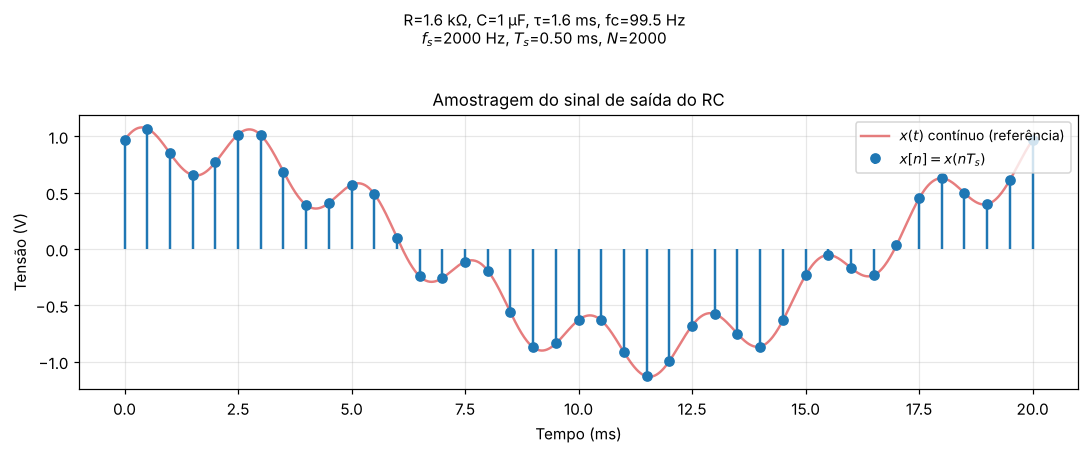

In [6]:
m = t_cont <= 0.020
mn = t <= 0.020

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_cont[m]*1e3, vout_c[m], color="tab:red", alpha=.6, label="$x(t)$ contínuo (referência)")
ml, sl, bl = ax.stem(t[mn]*1e3, x[mn], linefmt="tab:blue", markerfmt="o", basefmt=" ", label="$x[n]=x(nT_s)$")
ax.set_xlabel("Tempo (ms)"); ax.set_ylabel("Tensão (V)")
ax.set_title("Amostragem do sinal de saída do RC")
ax.legend(loc="upper right")
fig.suptitle(f"{PARAMS_RC}\n$f_s$={fs:.0f} Hz, $T_s$={Ts*1e3:.2f} ms, $N$={N}", y=1.02, fontsize=10)
fig.tight_layout(); salvar(fig, "03_amostragem"); plt.show()

## Etapa 4 – Análise espectral (FFT)

A DFT de $N$ pontos é calculada com a FFT:

$$X[k]=\sum_{n=0}^{N-1}x[n]\,e^{-j2\pi kn/N},\qquad f_k=k\,\frac{f_s}{N}$$

Para uma senoide $A\cos(2\pi f_0 t+\varphi)$ **exatamente** em um bin $k_0$, temos $X[k_0]=\frac{AN}{2}e^{j\varphi}$. Por isso:

- **amplitude** (espectro unilateral): $A_k=\dfrac{2|X[k]|}{N}$
- **fase**: $\angle X[k]$ (só faz sentido nos bins onde há energia; nos demais é ruído numérico, então são omitidos)
- **resolução espectral**: $\Delta f = f_s/N=1/T_{obs}$

A função `espectro()` abaixo será reaproveitada nas Etapas 5 e 6 (com opção de janela e *zero-padding*).

In [7]:
def espectro(x, fs, nfft=None, janela=None):
    """
    FFT unilateral com amplitude corrigida pelo ganho coerente da janela.
    Retorna (f, X, mag): frequências [Hz], FFT complexa e amplitude [V].
    """
    N = len(x)
    w = np.ones(N) if janela is None else janela
    nfft = N if nfft is None else nfft
    X = np.fft.rfft(x*w, nfft)
    f = np.fft.rfftfreq(nfft, 1/fs)
    mag = np.abs(X) / np.sum(w)           # = |X| / (N · ganho coerente)
    if nfft % 2 == 0: mag[1:-1] *= 2      # espectro unilateral (sem DC e sem Nyquist)
    else:             mag[1:]   *= 2
    return f, X, mag

f_k, X_k, mag_k = espectro(x, fs)
df = fs/N

# Picos do espectro
limiar = 0.05*mag_k.max()
pk, _ = signal.find_peaks(mag_k, height=limiar)

# Comparação medido × teórico
linhas = []
for (A, f0, ph), i in zip(sorted(comps_out, key=lambda c: c[1]), pk):
    linhas.append({
        "f teórica (Hz)": f0, "f medida (Hz)": f_k[i],
        "A teórica (V)": A,   "A medida (V)": mag_k[i],
        "fase teórica (°)": wrap(ph), "fase medida (°)": np.rad2deg(np.angle(X_k[i])),
    })
tab_fft = pd.DataFrame(linhas, index=["Pico 1", "Pico 2"])
print(f"Resolução espectral: Δf = fs/N = {fs:.0f}/{N} = {df:.2f} Hz")
display(tab_fft.round(4))

Resolução espectral: Δf = fs/N = 2000/2000 = 1.00 Hz


,f teórica (Hz),f medida (Hz),A teórica (V),A medida (V),fase teórica (°),fase medida (°)
Pico 1,50.0,50.0,0.8935,0.8935,-26.6866,-26.6866
Pico 2,400.0,400.0,0.2413,0.2413,-46.0350,-46.0350


### Visualização: tempo × magnitude × fase
Os três gráficos usam **o mesmo sinal**. No tempo vemos uma forma de onda "misturada"; no espectro de magnitude ela se **separa em duas linhas**, nas frequências 50 Hz e 400 Hz, com as amplitudes previstas pelo modelo ($A|H|$). No espectro de fase, os valores nesses picos coincidem com $\varphi_k+\angle H$.

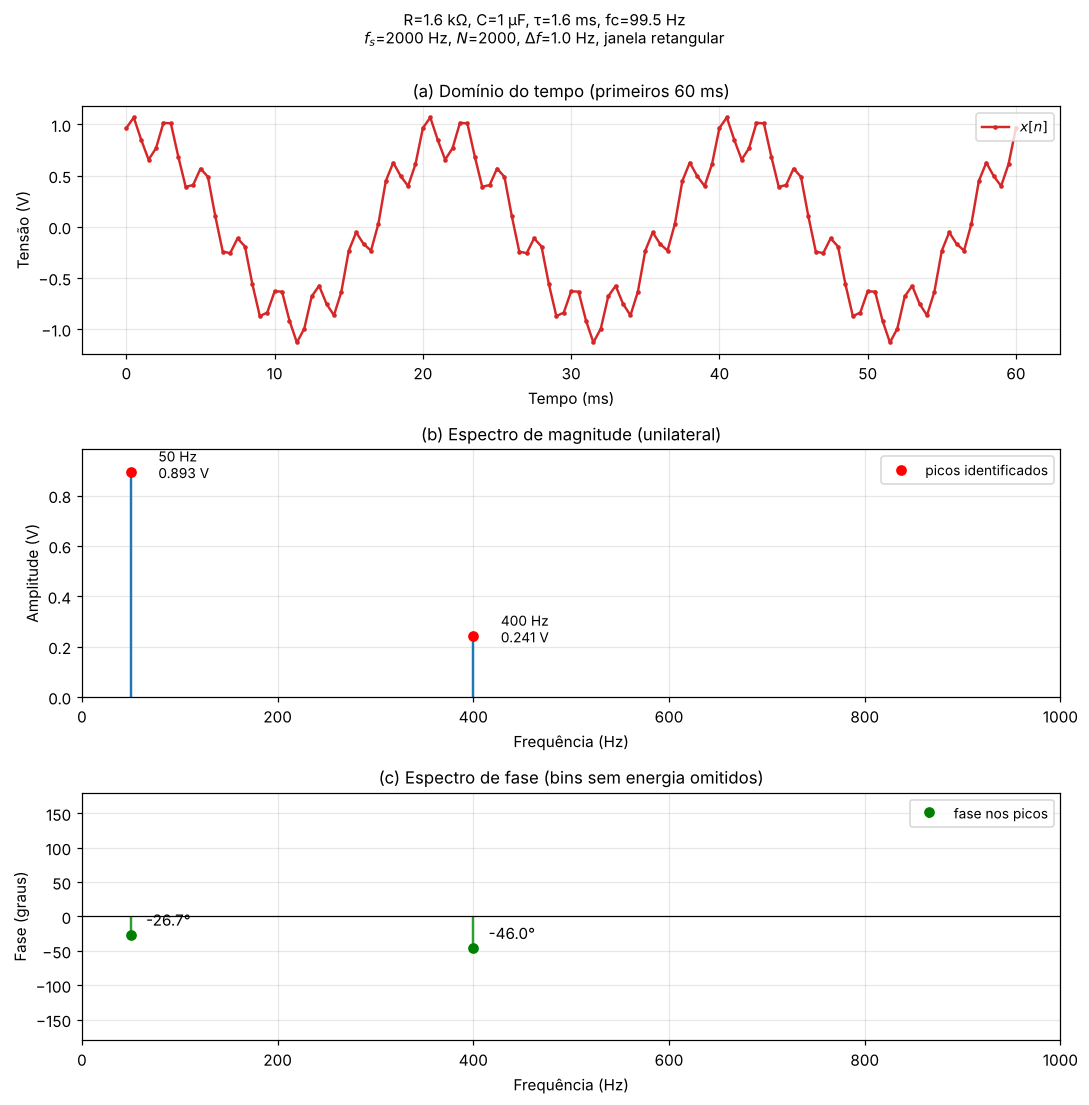

In [8]:
fig, axs = plt.subplots(3, 1, figsize=(10, 10))

# (a) Tempo
mn = t <= 0.060
axs[0].plot(t[mn]*1e3, x[mn], ".-", color="tab:red", ms=4, label="$x[n]$")
axs[0].set_xlabel("Tempo (ms)"); axs[0].set_ylabel("Tensão (V)")
axs[0].set_title("(a) Domínio do tempo (primeiros 60 ms)"); axs[0].legend(loc="upper right")

# (b) Magnitude
axs[1].stem(f_k, mag_k, linefmt="tab:blue", markerfmt=" ", basefmt=" ")
axs[1].plot(f_k[pk], mag_k[pk], "ro", label="picos identificados")
for i in pk:
    axs[1].annotate(f"{f_k[i]:.0f} Hz\n{mag_k[i]:.3f} V", (f_k[i], mag_k[i]),
                    textcoords="offset points", xytext=(18, -4), fontsize=9)
axs[1].set_xlim(0, fs/2); axs[1].set_ylim(0, 1.1*mag_k.max())
axs[1].set_xlabel("Frequência (Hz)"); axs[1].set_ylabel("Amplitude (V)")
axs[1].set_title("(b) Espectro de magnitude (unilateral)"); axs[1].legend(loc="upper right")

# (c) Fase (apenas bins com energia)
fase_deg = np.rad2deg(np.angle(X_k))
axs[2].stem(f_k[pk], fase_deg[pk], linefmt="tab:green", markerfmt="go", basefmt=" ", label="fase nos picos")
for i in pk:
    axs[2].annotate(f"{fase_deg[i]:.1f}°", (f_k[i], fase_deg[i]), textcoords="offset points", xytext=(10, 6))
axs[2].axhline(0, color="k", lw=.8)
axs[2].set_xlim(0, fs/2); axs[2].set_ylim(-180, 180)
axs[2].set_xlabel("Frequência (Hz)"); axs[2].set_ylabel("Fase (graus)")
axs[2].set_title("(c) Espectro de fase (bins sem energia omitidos)"); axs[2].legend(loc="upper right")

fig.suptitle(f"{PARAMS_RC}\n$f_s$={fs:.0f} Hz, $N$={N}, $\\Delta f$={df:.1f} Hz, janela retangular", y=1.0, fontsize=10)
fig.tight_layout(); salvar(fig, "04_espectro_fft"); plt.show()

**Interpretação do espectro**
- Há **apenas duas linhas**: 50 Hz e 400 Hz — exatamente as componentes do modelo temporal. Todo o resto do espectro é praticamente zero.
- A linha de 50 Hz tem amplitude ≈ 0,89 V (atenuação de ≈ 0,89 do RC); a de 400 Hz tem ≈ 0,24 V, ou seja, foi **muito mais atenuada** (o RC é passa-baixas).
- As fases medidas coincidem com $\varphi_k+\angle H(j2\pi f_k)$, confirmando que a FFT recupera **magnitude e fase** do modelo.
- A resolução é $\Delta f = 1$ Hz: duas componentes só seriam distinguíveis se estivessem separadas por mais do que ≈ 1 Hz.

## Etapa 5 – Aliasing

Vamos **reduzir propositalmente** $f_s$ até violar Nyquist ($f_s<800$ Hz). Para cada $f_s$ amostramos o mesmo sinal contínuo, por $T_{obs}=1$ s, e repetimos a FFT.

Testaremos $f_s\in\{2000,\,1000,\,700,\,500\}$ Hz:

| $f_s$ (Hz) | $f_s/2$ (Hz) | Situação |
|---|---|---|
| 2000 | 1000 | correto (400 Hz < 1000 Hz) |
| 1000 | 500 | correto (400 Hz < 500 Hz) |
| 700 | 350 | **aliasing** (400 Hz > 350 Hz) |
| 500 | 250 | **aliasing** (400 Hz > 250 Hz) |

### Explicação matemática
Amostrar $x(t)=A\cos(2\pi f t+\varphi)$ em $t=n/f_s$ dá $x[n]=A\cos\!\big(2\pi \tfrac{f}{f_s}n+\varphi\big)$. Como $n$ é inteiro, a fase pode ser deslocada de qualquer múltiplo de $2\pi n$:

$$\cos\!\Big(2\pi\frac{f}{f_s}n+\varphi\Big)=\cos\!\Big(2\pi\frac{f-m f_s}{f_s}n+\varphi\Big),\qquad m\in\mathbb{Z}$$

Ou seja, **$f$ e $f-mf_s$ geram exatamente as mesmas amostras**. A frequência que "aparece" no espectro é

$$f_{ap}=\big|\,f-\text{round}(f/f_s)\,f_s\,\big|\in[0,f_s/2]$$

Exemplo com $f_s=500$ Hz: $f_{ap}=|400-1\cdot 500|=100$ Hz. Como $\cos$ é par, a fase do alias troca de sinal: $-\varphi$.

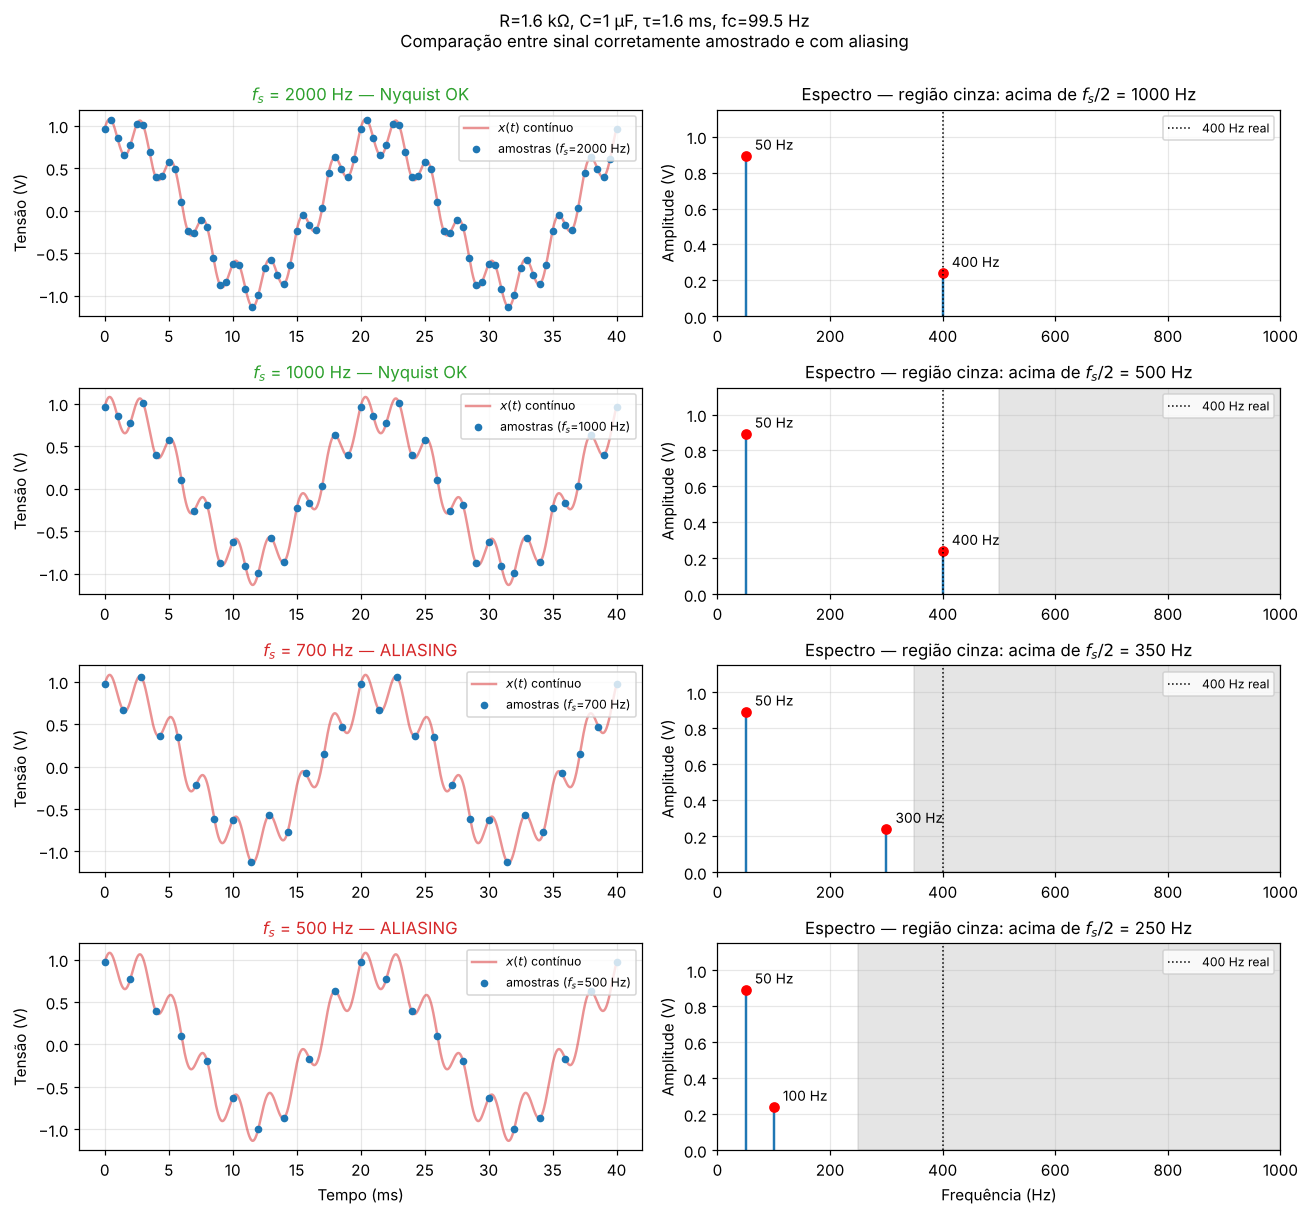

,fs/2 (Hz),Nyquist respeitado?,f aparente teórica (Hz),picos medidos (Hz)
fs (Hz),,,,
2000,1000.0,sim,50 e 400,"50, 400"
1000,500.0,sim,50 e 400,"50, 400"
700,350.0,NÃO,50 e 300,"50, 300"
500,250.0,NÃO,50 e 100,"50, 100"


In [9]:
fs_lista = [2000, 1000, 700, 500]
f_app = lambda f, fs_: abs(f - np.round(f/fs_)*fs_)      # frequência aparente

# Gráfico: coluna esquerda = tempo; direita = espectro
fig, axs = plt.subplots(len(fs_lista), 2, figsize=(12, 11))
linhas = []
mc = t_cont <= 0.040

for r, fs_i in enumerate(fs_lista):
    t_i, x_i = amostrar(fs_i)
    f_i, X_i, mag_i = espectro(x_i, fs_i)
    pk_i, _ = signal.find_peaks(mag_i, height=0.05*mag_i.max())
    ok = fs_i > 2*f_max

    # tempo
    ax = axs[r, 0]
    ax.plot(t_cont[mc]*1e3, vout_c[mc], color="tab:red", alpha=.5, label="$x(t)$ contínuo")
    mi = t_i <= 0.040
    ax.plot(t_i[mi]*1e3, x_i[mi], "o", color="tab:blue", ms=4, label=f"amostras ($f_s$={fs_i} Hz)")
    ax.set_ylabel("Tensão (V)")
    ax.set_title(f"$f_s$ = {fs_i} Hz — " + ("Nyquist OK" if ok else "ALIASING"),
                 color=("tab:green" if ok else "tab:red"))
    ax.legend(loc="upper right", fontsize=8)

    # espectro
    ax = axs[r, 1]
    ax.stem(f_i, mag_i, linefmt="tab:blue", markerfmt=" ", basefmt=" ")
    ax.plot(f_i[pk_i], mag_i[pk_i], "ro")
    for i in pk_i:
        ax.annotate(f"{f_i[i]:.0f} Hz", (f_i[i], mag_i[i]), textcoords="offset points", xytext=(6, 4), fontsize=9)
    ax.axvspan(fs_i/2, 1000, color="gray", alpha=.2)
    ax.axvline(f2, color="k", ls=":", lw=1, label=f"{f2:.0f} Hz real")
    ax.set_xlim(0, 1000); ax.set_ylim(0, 1.15)
    ax.set_ylabel("Amplitude (V)")
    ax.set_title(f"Espectro — região cinza: acima de $f_s/2$ = {fs_i/2:.0f} Hz")
    ax.legend(loc="upper right", fontsize=8)

    linhas.append({
        "fs (Hz)": fs_i, "fs/2 (Hz)": fs_i/2, "Nyquist respeitado?": "sim" if ok else "NÃO",
        "f aparente teórica (Hz)": f"{f_app(f1, fs_i):.0f} e {f_app(f2, fs_i):.0f}",
        "picos medidos (Hz)": ", ".join(f"{f_i[i]:.0f}" for i in pk_i),
    })

axs[-1, 0].set_xlabel("Tempo (ms)"); axs[-1, 1].set_xlabel("Frequência (Hz)")
fig.suptitle(f"{PARAMS_RC}\nComparação entre sinal corretamente amostrado e com aliasing", y=1.0, fontsize=11)
fig.tight_layout(); salvar(fig, "05_aliasing_espectros"); plt.show()

display(pd.DataFrame(linhas).set_index("fs (Hz)"))

**O que o gráfico mostra**
- Com $f_s=2000$ e $1000$ Hz: picos em **50 e 400 Hz** (corretos).
- Com $f_s=700$ Hz: o pico de 400 Hz "dobra" e aparece em $|400-700|=300$ Hz.
- Com $f_s=500$ Hz: aparece em $|400-500|=100$ Hz — e **nada no espectro avisa** que esse pico é falso. A amplitude (≈ 0,24 V) é preservada, só a frequência é errada.

### Prova visual: o alias tem as mesmas amostras
Abaixo isolamos só a componente de 400 Hz, amostrada a 500 Hz. A senoide de 100 Hz (com fase $-\varphi$) passa **exatamente por todas as amostras**.

Alias reproduz as amostras? True
f = 400 Hz, fs = 500 Hz -> f_aparente = 100 Hz, fase do alias = 46.0°


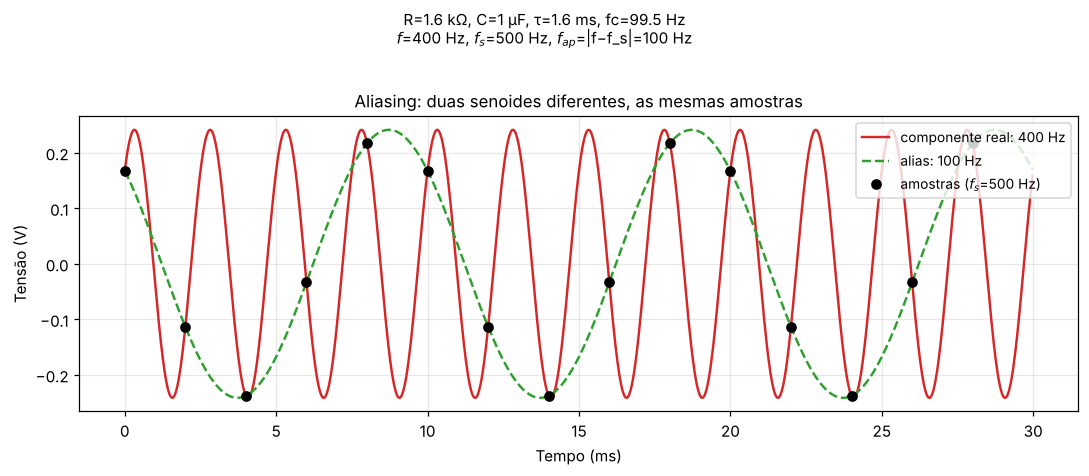

In [10]:
A2o, f2o, ph2o = comps_out[1]
fs_a = 500
n_a = np.arange(int(0.030*fs_a))
t_c = np.arange(0, 0.030, 1/fs_cont)

x_orig  = A2o*np.cos(2*np.pi*f2o*t_c + ph2o)
x_samp  = A2o*np.cos(2*np.pi*f2o*n_a/fs_a + ph2o)

f_signed = f2o - np.round(f2o/fs_a)*fs_a       # 400 - 500 = -100
f_al     = abs(f_signed)
ph_al    = ph2o if f_signed >= 0 else -ph2o    # cos é par -> fase troca de sinal
x_alias  = A2o*np.cos(2*np.pi*f_al*t_c + ph_al)

# verificação numérica: o alias reproduz exatamente as amostras
x_samp_alias = A2o*np.cos(2*np.pi*f_al*n_a/fs_a + ph_al)
print("Alias reproduz as amostras?", np.allclose(x_samp, x_samp_alias))
print(f"f = {f2o:.0f} Hz, fs = {fs_a} Hz -> f_aparente = {f_al:.0f} Hz, fase do alias = {np.rad2deg(ph_al):.1f}°")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t_c*1e3, x_orig, color="tab:red", label=f"componente real: {f2o:.0f} Hz")
ax.plot(t_c*1e3, x_alias, "--", color="tab:green", label=f"alias: {f_al:.0f} Hz")
ax.plot(n_a/fs_a*1e3, x_samp, "ko", ms=6, label=f"amostras ($f_s$={fs_a} Hz)")
ax.set_xlabel("Tempo (ms)"); ax.set_ylabel("Tensão (V)")
ax.set_title("Aliasing: duas senoides diferentes, as mesmas amostras")
ax.legend(loc="upper right")
fig.suptitle(f"{PARAMS_RC}\n$f$={f2o:.0f} Hz, $f_s$={fs_a} Hz, $f_{{ap}}$=|f−f_s|={f_al:.0f} Hz", y=1.02, fontsize=10)
fig.tight_layout(); salvar(fig, "06_aliasing_prova"); plt.show()

## Etapa 6 – Janelamento

### Condição com vazamento espectral
Voltamos a $f_s=2000$ Hz, mas agora usamos **$N=1013$ amostras** (≈ 0,5065 s). Nesse intervalo, 50 Hz tem 25,3 ciclos e 400 Hz tem 202,6 ciclos: **não é um número inteiro** de períodos. A FFT "enxerga" um sinal periódico com descontinuidade nas bordas, e a energia de cada linha **vaza** para bins vizinhos.

Comparamos três janelas $w[n]$ (sinal analisado: $x[n]\,w[n]$):

- **Retangular** (sem janela): $w[n]=1$
- **Hann:** $w[n]=0{,}5-0{,}5\cos\!\big(2\pi n/N\big)$
- **Hamming:** $w[n]=0{,}54-0{,}46\cos\!\big(2\pi n/N\big)$

Para ler os picos com precisão, usamos *zero-padding* ($N_{FFT}=2^{16}$), que só interpola o espectro (não melhora a resolução real). As amplitudes são corrigidas pelo **ganho coerente** $\sum w[n]/N$.

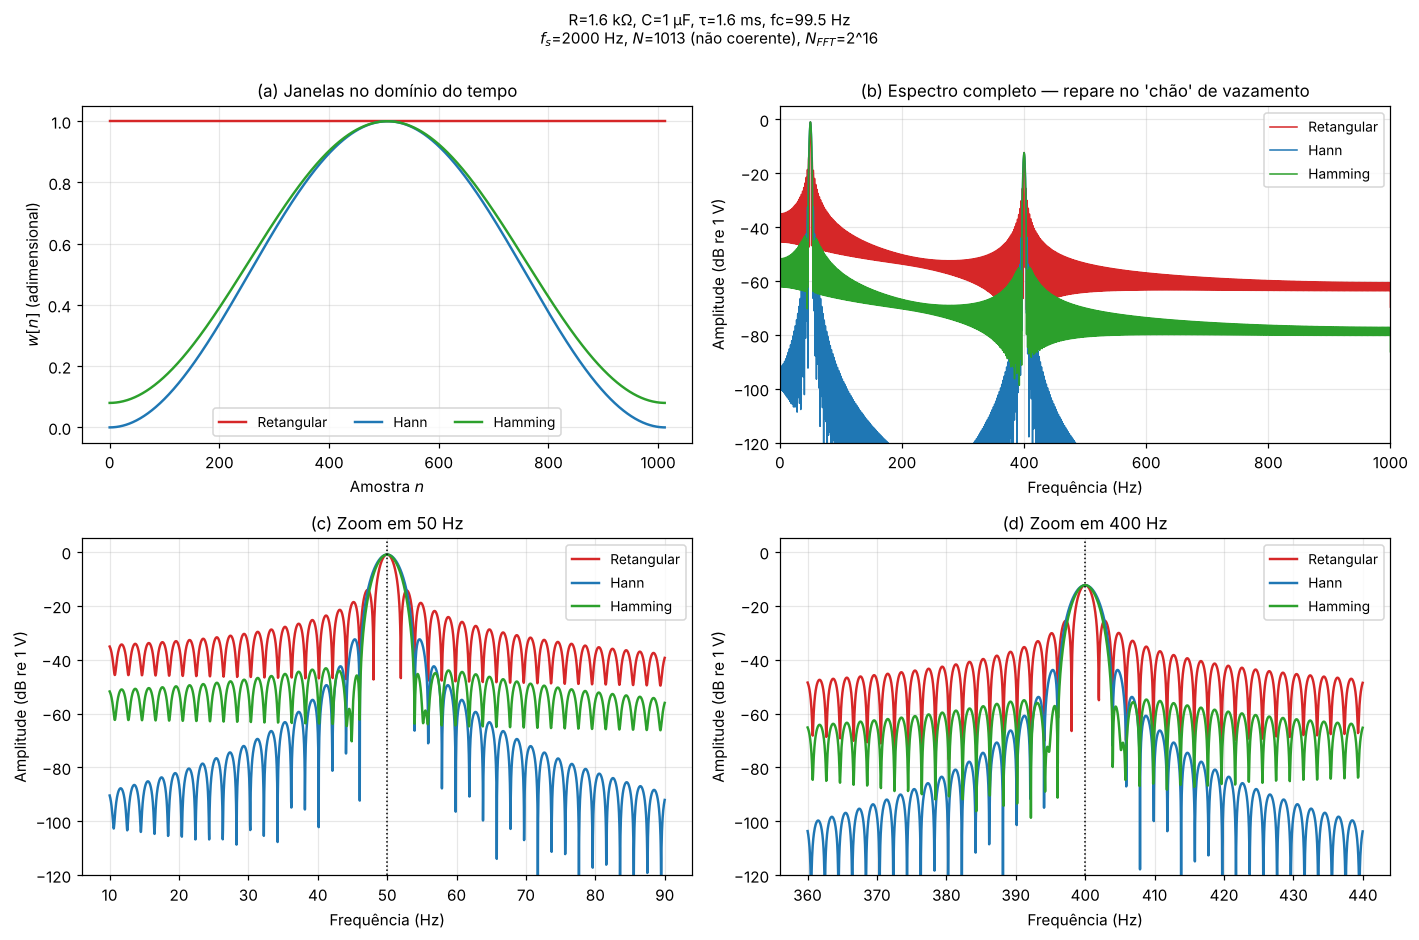

,f pico 50 Hz (Hz),A pico 50 Hz (V),f pico 400 Hz (Hz),A pico 400 Hz (V),vazamento em 200 Hz (dB)
janela,,,,,
Retangular,49.9878,0.8968,399.9939,0.2427,-52.1967
Hann,49.9878,0.8935,399.9939,0.2413,-139.1308
Hamming,49.9878,0.8939,399.9939,0.2415,-68.7849


Valores verdadeiros: A(50 Hz)=0.8935 V, A(400 Hz)=0.2413 V


In [11]:
fs6, N6 = 2000.0, 1013
t6, x6 = amostrar(fs6, N=N6)

JANELAS = {
    "Retangular": np.ones(N6),
    "Hann":       signal.windows.hann(N6, sym=False),
    "Hamming":    signal.windows.hamming(N6, sym=False),
}
CORES = {"Retangular": "tab:red", "Hann": "tab:blue", "Hamming": "tab:green"}
nfft6 = 2**16
ESP6 = {nome: espectro(x6, fs6, nfft6, w) for nome, w in JANELAS.items()}
db = lambda a: 20*np.log10(np.maximum(a, 1e-12))

fig, axs = plt.subplots(2, 2, figsize=(13, 8.5))

# (a) janelas no tempo
for nome, w in JANELAS.items():
    axs[0, 0].plot(np.arange(N6), w, color=CORES[nome], label=nome)
axs[0, 0].set_xlabel("Amostra $n$"); axs[0, 0].set_ylabel("$w[n]$ (adimensional)")
axs[0, 0].set_title("(a) Janelas no domínio do tempo"); axs[0, 0].legend(loc="lower center", ncol=3)

# (b) espectro completo em dB
for nome, (f_, X_, mag_) in ESP6.items():
    axs[0, 1].plot(f_, db(mag_), color=CORES[nome], lw=1, label=nome)
axs[0, 1].set_xlim(0, 1000); axs[0, 1].set_ylim(-120, 5)
axs[0, 1].set_xlabel("Frequência (Hz)"); axs[0, 1].set_ylabel("Amplitude (dB re 1 V)")
axs[0, 1].set_title("(b) Espectro completo — repare no 'chão' de vazamento"); axs[0, 1].legend(loc="upper right")

# (c) zoom 50 Hz  /  (d) zoom 400 Hz
for ax, (c, lar, rot) in zip([axs[1, 0], axs[1, 1]], [(f1, 40, "(c) Zoom em 50 Hz"), (f2, 40, "(d) Zoom em 400 Hz")]):
    for nome, (f_, X_, mag_) in ESP6.items():
        sel = (f_ > c-lar) & (f_ < c+lar)
        ax.plot(f_[sel], db(mag_[sel]), color=CORES[nome], label=nome)
    ax.axvline(c, color="k", ls=":", lw=1)
    ax.set_ylim(-120, 5)
    ax.set_xlabel("Frequência (Hz)"); ax.set_ylabel("Amplitude (dB re 1 V)")
    ax.set_title(rot); ax.legend(loc="upper right")

fig.suptitle(f"{PARAMS_RC}\n$f_s$={fs6:.0f} Hz, $N$={N6} (não coerente), $N_{{FFT}}$=2^16", y=1.0, fontsize=10)
fig.tight_layout(); salvar(fig, "07_janelamento_espectros"); plt.show()

# Tabela de estimativas
linhas = []
for nome, (f_, X_, mag_) in ESP6.items():
    r = {"janela": nome}
    for rot, f0, A0 in [("50 Hz", f1, comps_out[0][0]), ("400 Hz", f2, comps_out[1][0])]:
        sel = np.where((f_ > f0-10) & (f_ < f0+10))[0]
        i = sel[np.argmax(mag_[sel])]
        r[f"f pico {rot} (Hz)"] = f_[i]
        r[f"A pico {rot} (V)"] = mag_[i]
    i200 = np.argmin(abs(f_ - 200))
    r["vazamento em 200 Hz (dB)"] = db(mag_[i200])
    linhas.append(r)
display(pd.DataFrame(linhas).set_index("janela").round(4))
print(f"Valores verdadeiros: A(50 Hz)={comps_out[0][0]:.4f} V, A(400 Hz)={comps_out[1][0]:.4f} V")

### Propriedades das janelas (lóbulo principal e lóbulos laterais)
Para comparar as janelas **sem depender do sinal**, calculamos a resposta em frequência de cada uma (janela de 64 pontos, com muito *zero-padding*) e medimos numericamente:

- **largura do lóbulo principal** (entre os primeiros nulos, em bins);
- **nível do maior lóbulo lateral** (PSL, em dB, relativo ao pico);
- **ENBW** (largura de banda equivalente de ruído, em bins): $\text{ENBW}=N\sum w^2\big/(\sum w)^2$, medida de perda de resolução.

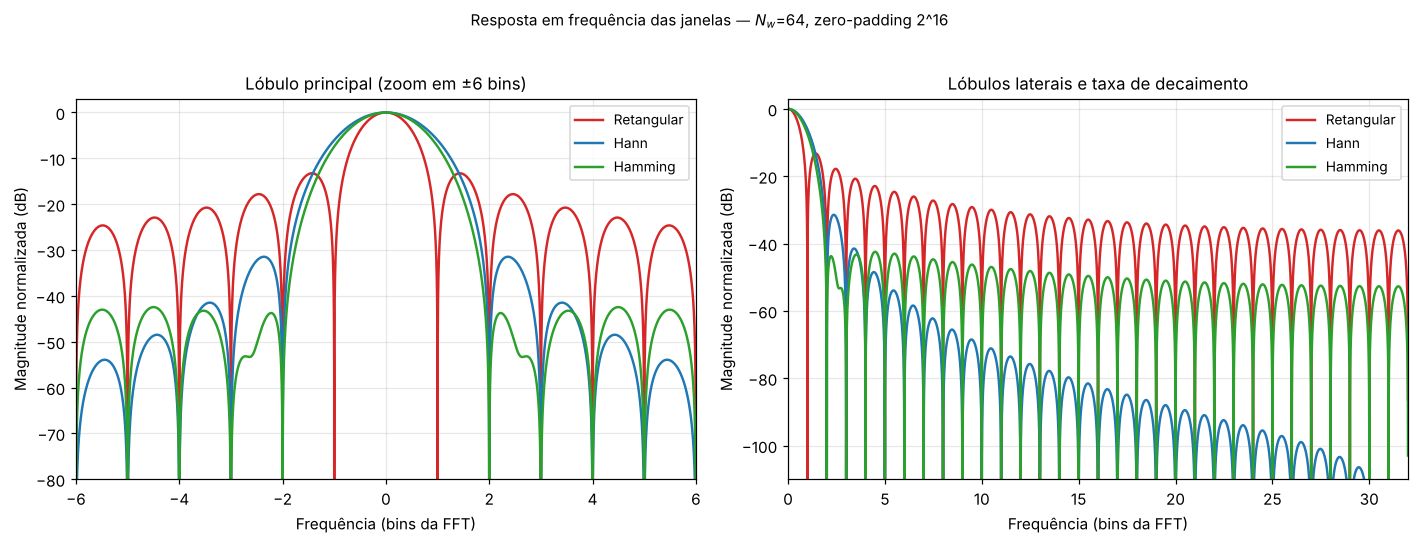

,largura do lóbulo principal (bins),maior lóbulo lateral (dB),ENBW (bins)
Retangular,2.0,-13.25,1.00
Hann,4.0,-31.47,1.50
Hamming,4.0,-42.45,1.36


In [12]:
def resposta_janela(w, nfft=2**16):
    W = np.fft.fftshift(np.fft.fft(w, nfft))
    mag = np.abs(W)/np.sum(w)
    bins = np.fft.fftshift(np.fft.fftfreq(nfft))*len(w)     # frequência em bins
    return bins, db(mag)

def metricas(w):
    b, Wdb = resposta_janela(w)
    pos = b >= 0
    b_, W_ = b[pos], Wdb[pos]
    i_nulo = np.argmax(np.diff(W_) > 0)          # primeiro vale = primeiro nulo
    largura = 2*b_[i_nulo]                       # largura entre nulos (bins)
    psl = W_[i_nulo:].max()                      # maior lóbulo lateral (dB)
    enbw = len(w)*np.sum(w**2)/np.sum(w)**2
    return largura, psl, enbw

Nw = 64
JW = {"Retangular": np.ones(Nw),
      "Hann":       signal.windows.hann(Nw, sym=False),
      "Hamming":    signal.windows.hamming(Nw, sym=False)}

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for nome, w in JW.items():
    b, Wdb = resposta_janela(w)
    axs[0].plot(b, Wdb, color=CORES[nome], label=nome)
    axs[1].plot(b, Wdb, color=CORES[nome], label=nome)
axs[0].set_xlim(-6, 6);  axs[0].set_ylim(-80, 3)
axs[1].set_xlim(0, 32);  axs[1].set_ylim(-110, 3)
axs[0].set_title("Lóbulo principal (zoom em ±6 bins)")
axs[1].set_title("Lóbulos laterais e taxa de decaimento")
for ax in axs:
    ax.set_xlabel("Frequência (bins da FFT)"); ax.set_ylabel("Magnitude normalizada (dB)"); ax.legend()
fig.suptitle(f"Resposta em frequência das janelas — $N_w$={Nw}, zero-padding 2^16", y=1.02, fontsize=10)
fig.tight_layout(); salvar(fig, "08_janelas_resposta"); plt.show()

tab_jan = pd.DataFrame(
    [metricas(w) for w in JW.values()], index=JW.keys(),
    columns=["largura do lóbulo principal (bins)", "maior lóbulo lateral (dB)", "ENBW (bins)"])
display(tab_jan.round(2))

### Resolução × vazamento (dois experimentos)
O compromisso do janelamento aparece em duas situações opostas. Usamos $f_s=2000$ Hz e $N=256$ ($\Delta f\approx 7{,}8$ Hz):

1. **Resolução:** duas senoides de mesma amplitude, muito próximas (100 Hz e 110 Hz). Quem consegue separá-las?
2. **Faixa dinâmica:** uma senoide forte (100 Hz, 1 V) e uma **muito fraca** (180 Hz, 3 mV ≈ −50 dB). O vazamento da forte esconde a fraca?

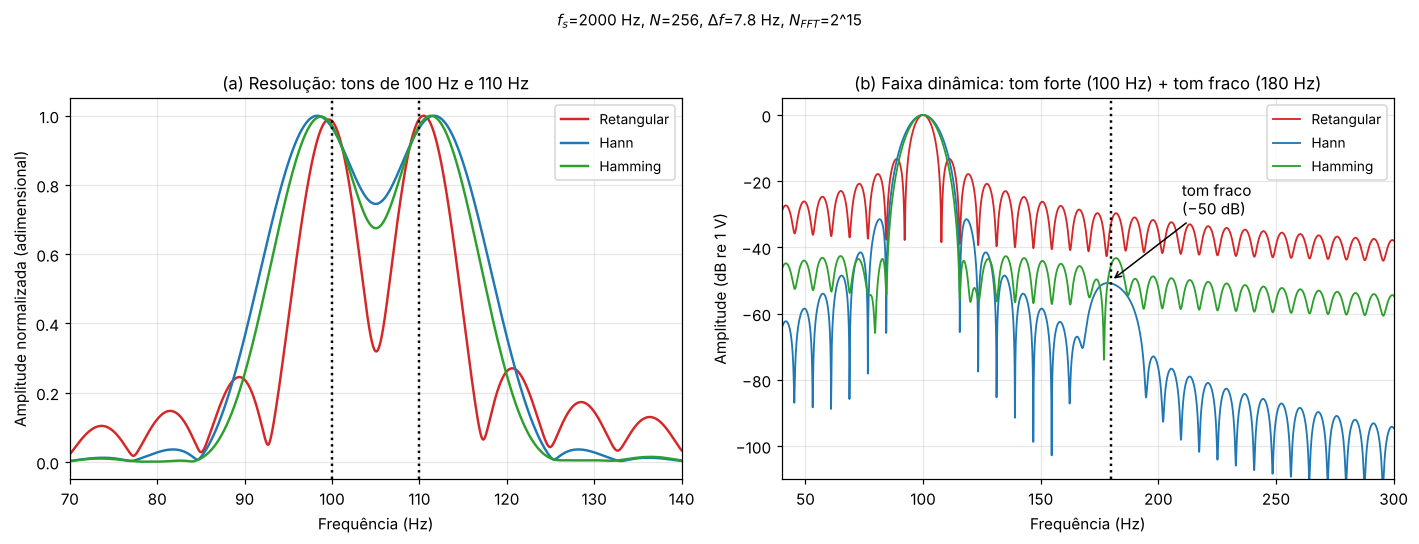

In [13]:
fsC, NC = 2000.0, 256
tC = np.arange(NC)/fsC
JC = {"Retangular": np.ones(NC),
      "Hann":       signal.windows.hann(NC, sym=False),
      "Hamming":    signal.windows.hamming(NC, sym=False)}

xC1 = np.cos(2*np.pi*100*tC) + np.cos(2*np.pi*110*tC)           # resolução
xC2 = np.cos(2*np.pi*100*tC) + 0.003*np.cos(2*np.pi*180*tC)     # faixa dinâmica

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for nome, w in JC.items():
    f_, _, m1 = espectro(xC1, fsC, 2**15, w)
    f_, _, m2 = espectro(xC2, fsC, 2**15, w)
    axs[0].plot(f_, m1/m1.max(), color=CORES[nome], label=nome)
    axs[1].plot(f_, db(m2), color=CORES[nome], label=nome, lw=1.2)

axs[0].set_xlim(70, 140); axs[0].axvline(100, color="k", ls=":"); axs[0].axvline(110, color="k", ls=":")
axs[0].set_xlabel("Frequência (Hz)"); axs[0].set_ylabel("Amplitude normalizada (adimensional)")
axs[0].set_title("(a) Resolução: tons de 100 Hz e 110 Hz"); axs[0].legend()

axs[1].set_xlim(40, 300); axs[1].set_ylim(-110, 5)
axs[1].axvline(180, color="k", ls=":"); axs[1].annotate("tom fraco\n(−50 dB)", (180, -50), xytext=(210, -30),
                                                        arrowprops=dict(arrowstyle="->"))
axs[1].set_xlabel("Frequência (Hz)"); axs[1].set_ylabel("Amplitude (dB re 1 V)")
axs[1].set_title("(b) Faixa dinâmica: tom forte (100 Hz) + tom fraco (180 Hz)"); axs[1].legend(loc="upper right")

fig.suptitle(f"$f_s$={fsC:.0f} Hz, $N$={NC}, $\\Delta f$={fsC/NC:.1f} Hz, $N_{{FFT}}$=2^15", y=1.02, fontsize=10)
fig.tight_layout(); salvar(fig, "09_janelamento_resolucao"); plt.show()

**Discussão do janelamento**

| Janela | Lóbulo principal | Lóbulos laterais | Vazamento | Resolução |
|---|---|---|---|---|
| Retangular | o **mais estreito** (≈ 2 bins) | o **mais altos** (≈ −13 dB) e decaem devagar | **alto** | **melhor** (separa tons próximos) |
| Hann | ≈ 4 bins (mais largo) | ≈ −31 dB, decaem **rápido** (18 dB/oitava) | baixo longe do pico | pior |
| Hamming | ≈ 4 bins | ≈ −42 dB (1º lóbulo bem baixo), mas decaem devagar | baixo perto do pico | pior |

- **Vazamento:** com frequências não coerentes, a janela retangular espalha energia por todo o espectro (ver "chão" alto na figura 07). Hann e Hamming reduzem muito esse chão.
- **Lóbulo principal:** quanto menor o vazamento, mais largo o lóbulo principal. É o **compromisso fundamental** entre vazamento e resolução.
- **Resolução:** na figura 09(a), a retangular separa os dois tons com um vale profundo entre eles; com Hann/Hamming o vale fica bem mais raso (os picos "se misturam").
- **Faixa dinâmica:** na figura 09(b), o tom fraco (−50 dB) fica **escondido** sob o vazamento do tom forte com a janela retangular e quase no mesmo nível dos lóbulos laterais com Hamming; só com **Hann** ele aparece claramente acima do vazamento.
- A escolha depende do objetivo: **resolução** → retangular; **detectar componentes fracas / reduzir vazamento** → Hann ou Hamming.

## Etapa 7 – Modelo contínuo (plano-s)

O sistema contínuo associado ao circuito é o de **1ª ordem**:

$$H(s)=\frac{1}{\tau s+1}=\frac{1/\tau}{s+1/\tau}$$

- **Polo:** $s=-1/\tau$ (real, negativo)
- **Zeros:** nenhum
- **Respostas temporais:**
  - impulso: $h(t)=\dfrac{1}{\tau}e^{-t/\tau}u(t)$
  - degrau: $y(t)=\big(1-e^{-t/\tau}\big)u(t)$

O polo no semiplano esquerdo ($\operatorname{Re}\{s\}<0$) significa **sistema estável**; quanto mais à esquerda, mais rápida a resposta ($\tau$ menor).

Também mostramos a resposta em frequência $H(j\omega)$ (Bode), marcando as duas frequências do nosso sinal. No plano-s, essas frequências ficam sobre o eixo $j\omega$.

H(s) = 1 / (0.0016·s + 1)
Polo(s): [-625.]  rad/s   (= -1/τ = -625.0 )
Zeros: nenhum
Estável? True


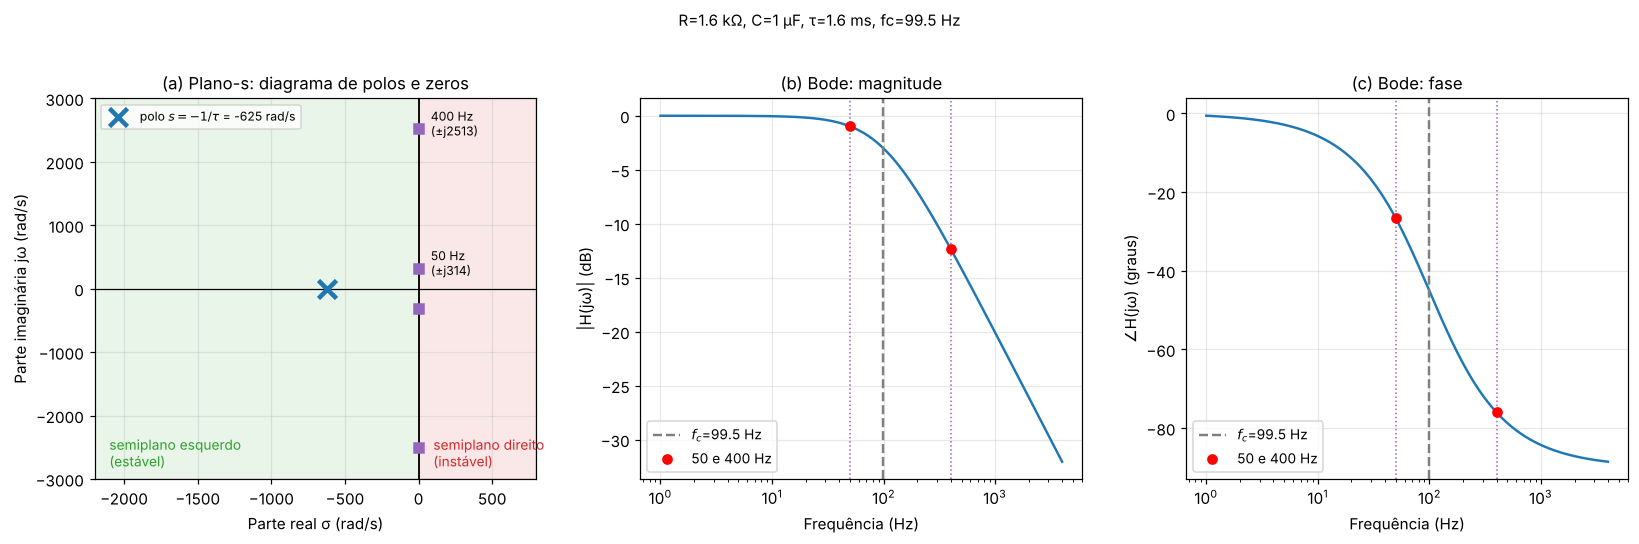

In [14]:
sys_c = signal.TransferFunction([1.0], [tau, 1.0])
polos_c, zeros_c = sys_c.poles, sys_c.zeros
print(f"H(s) = 1 / ({tau:.4g}·s + 1)")
print("Polo(s):", polos_c, " rad/s   (= -1/τ =", -1/tau, ")")
print("Zeros:", zeros_c if len(zeros_c) else "nenhum")
print("Estável?", bool(np.all(polos_c.real < 0)))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))

# (a) plano-s
ax = axs[0]
xl, yl = (-2200, 800), (-3000, 3000)
ax.axvspan(xl[0], 0, color="tab:green", alpha=.10); ax.axvspan(0, xl[1], color="tab:red", alpha=.10)
ax.axhline(0, color="k", lw=.8); ax.axvline(0, color="k", lw=1.2)
ax.plot(polos_c.real, polos_c.imag, "x", color="tab:blue", ms=12, mew=3, label=f"polo $s=-1/\\tau$ = {polos_c[0].real:.0f} rad/s")
for fx, rot in [(f1, "50 Hz"), (f2, "400 Hz")]:
    w_ = 2*np.pi*fx
    ax.plot([0, 0], [w_, -w_], "s", color="tab:purple", ms=6)
    ax.annotate(f"{rot}\n(±j{w_:.0f})", (0, w_), textcoords="offset points", xytext=(8, -4), fontsize=8)
ax.text(-2100, -2800, "semiplano esquerdo\n(estável)", color="tab:green", fontsize=9)
ax.text(100, -2800, "semiplano direito\n(instável)", color="tab:red", fontsize=9)
ax.set_xlim(xl); ax.set_ylim(yl)
ax.set_xlabel("Parte real σ (rad/s)"); ax.set_ylabel("Parte imaginária jω (rad/s)")
ax.set_title("(a) Plano-s: diagrama de polos e zeros"); ax.legend(loc="upper left", fontsize=8)

# (b,c) Bode
fb = np.logspace(0, 3.6, 600)
Hb = H_jw(fb)
axs[1].semilogx(fb, 20*np.log10(abs(Hb)), color="tab:blue")
axs[2].semilogx(fb, np.rad2deg(np.angle(Hb)), color="tab:blue")
for ax in axs[1:]:
    ax.axvline(fc, color="gray", ls="--", label=f"$f_c$={fc:.1f} Hz")
    for fx in (f1, f2): ax.axvline(fx, color="tab:purple", ls=":", lw=1)
axs[1].plot([f1, f2], [20*np.log10(abs(H_jw(f1))), 20*np.log10(abs(H_jw(f2)))], "ro", label="50 e 400 Hz")
axs[2].plot([f1, f2], [np.rad2deg(np.angle(H_jw(f1))), np.rad2deg(np.angle(H_jw(f2)))], "ro", label="50 e 400 Hz")
axs[1].set_title("(b) Bode: magnitude"); axs[1].set_ylabel("|H(jω)| (dB)")
axs[2].set_title("(c) Bode: fase");      axs[2].set_ylabel("∠H(jω) (graus)")
for ax in axs[1:]:
    ax.set_xlabel("Frequência (Hz)"); ax.legend(loc="lower left")

fig.suptitle(f"{PARAMS_RC}", y=1.02, fontsize=10)
fig.tight_layout(); salvar(fig, "10_plano_s_bode"); plt.show()

### Resposta temporal do sistema contínuo
Três gráficos:

1. **Resposta ao impulso** $h(t)$ — decaimento exponencial com constante $\tau$.
2. **Resposta ao degrau** — sobe até 63,2 % do valor final em $t=\tau$ e ≈ 99 % em $5\tau$.
3. **Resposta à nossa entrada $v_{in}(t)$** (simulada com `lsim`, condições iniciais nulas) comparada ao modelo de **regime permanente** da Etapa 2. A diferença é o **transitório** $\propto e^{-t/\tau}$, que desaparece após ≈ $5\tau=8$ ms. Isso valida o sinal $x(t)$ usado nas etapas anteriores.

Erro máximo |lsim − regime permanente| para t > 5τ (8 ms): 6.47e-03 V


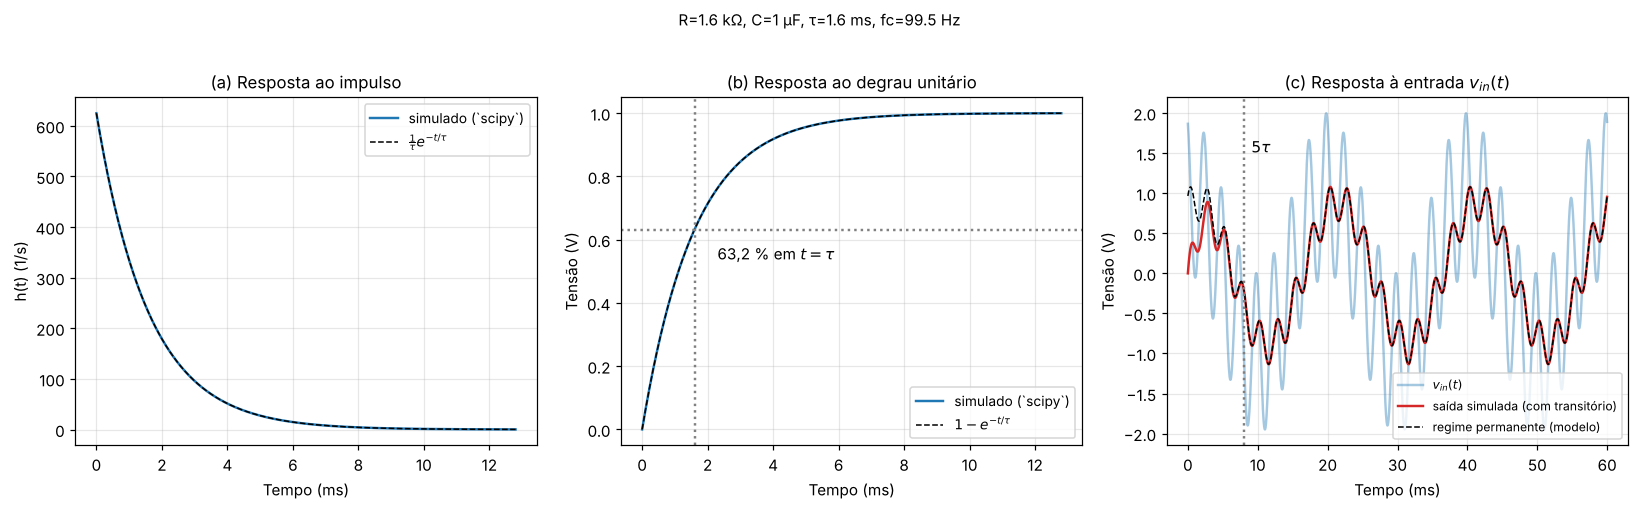

In [15]:
t_h = np.linspace(0, 8*tau, 800)
h_t = (1/tau)*np.exp(-t_h/tau)
y_deg = 1 - np.exp(-t_h/tau)

# Simulação numérica do circuito com a entrada v_in(t) (estado inicial = 0)
mm = t_cont <= 0.060
t_l = t_cont[mm]
_, y_lsim, _ = signal.lsim(sys_c, U=vin_c[mm], T=t_l)
erro = y_lsim - vout_c[mm]
apos = t_l > 5*tau
print(f"Erro máximo |lsim − regime permanente| para t > 5τ ({5*tau*1e3:.0f} ms): {abs(erro[apos]).max():.2e} V")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))

# (a) impulso
t_i, h_i = signal.impulse(sys_c, T=t_h)
axs[0].plot(t_i*1e3, h_i, color="tab:blue", label="simulado (`scipy`)")
axs[0].plot(t_h*1e3, h_t, "k--", lw=1, label=r"$\frac{1}{\tau}e^{-t/\tau}$")
axs[0].set_title("(a) Resposta ao impulso"); axs[0].set_xlabel("Tempo (ms)"); axs[0].set_ylabel("h(t) (1/s)"); axs[0].legend()

# (b) degrau
t_s, y_s = signal.step(sys_c, T=t_h)
axs[1].plot(t_s*1e3, y_s, color="tab:blue", label="simulado (`scipy`)")
axs[1].plot(t_h*1e3, y_deg, "k--", lw=1, label=r"$1-e^{-t/\tau}$")
axs[1].axhline(0.632, color="gray", ls=":"); axs[1].axvline(tau*1e3, color="gray", ls=":")
axs[1].annotate("63,2 % em $t=\\tau$", (tau*1e3, .632), textcoords="offset points", xytext=(15, -20))
axs[1].set_title("(b) Resposta ao degrau unitário"); axs[1].set_xlabel("Tempo (ms)"); axs[1].set_ylabel("Tensão (V)"); axs[1].legend(loc="lower right")

# (c) resposta à entrada real
axs[2].plot(t_l*1e3, vin_c[mm], color="tab:blue", alpha=.4, label="$v_{in}(t)$")
axs[2].plot(t_l*1e3, y_lsim, color="tab:red", label="saída simulada (com transitório)")
axs[2].plot(t_l*1e3, vout_c[mm], "k--", lw=1, label="regime permanente (modelo)")
axs[2].axvline(5*tau*1e3, color="gray", ls=":"); axs[2].annotate("$5\\tau$", (5*tau*1e3, 1.5), xytext=(5, 0), textcoords="offset points")
axs[2].set_title("(c) Resposta à entrada $v_{in}(t)$"); axs[2].set_xlabel("Tempo (ms)"); axs[2].set_ylabel("Tensão (V)")
axs[2].legend(loc="lower right", fontsize=8)

fig.suptitle(f"{PARAMS_RC}", y=1.02, fontsize=10)
fig.tight_layout(); salvar(fig, "11_respostas_temporais"); plt.show()

## Etapa 8 – Modelo discreto (plano-z)

Obtemos $H(z)$ discretizando o RC pelo método **ZOH** (*zero-order hold*), que é o equivalente natural de um sistema com DAC/ADC. Para $H(s)=\dfrac{1}{\tau s+1}$ e $a=e^{-T_s/\tau}$:

$$H(z)=\frac{B(z)}{A(z)}=\frac{1-a}{z-a}=\frac{(1-a)\,z^{-1}}{1-a\,z^{-1}}$$

que corresponde à equação de diferenças $y[n]=a\,y[n-1]+(1-a)\,u[n-1]$.

- **Polo:** $z=a=e^{-T_s/\tau}$ (real, entre 0 e 1)
- **Zeros:** nenhum zero finito (há um atraso de uma amostra, $z^{-1}$)
- **Resposta ao impulso:** $h[n]=(1-a)\,a^{\,n-1}\,u[n-1]$
- **Estabilidade:** um sistema causal é estável se **todos os polos estão dentro do círculo unitário** ($|p|<1$), equivalente a $\sum|h[n]|<\infty$.

> Alternativa comum: a transformação bilinear (Tustin), que gera um zero em $z=-1$. Escolhemos ZOH por ser exata nas amostras para entradas em degrau.

In [16]:
num_d, den_d, _ = signal.cont2discrete(([1.0], [tau, 1.0]), Ts, method="zoh")
b_d, a_d = np.squeeze(num_d), np.squeeze(den_d)          # coeficientes em potências de z^-1
b_z = np.trim_zeros(b_d, 'f')                            # remove o zero à esquerda (atraso z^-1)
z_d, p_d, k_d = signal.tf2zpk(b_z, a_d)                  # zeros, polos e ganho

a_exp = np.exp(-Ts/tau)
print(f"Ts = {Ts*1e3:.2f} ms   a = exp(-Ts/τ) = {a_exp:.5f}")
print(f"B(z^-1) = {b_d}   |   A(z^-1) = {a_d}")
print(f"H(z) = {k_d:.5f} / (z - {p_d[0].real:.5f})")
print("Polos:", p_d, "  |p| =", abs(p_d))
print("Zeros finitos:", z_d if len(z_d) else "nenhum")
print("Estável?", bool(np.all(abs(p_d) < 1)))
assert np.isclose(p_d[0].real, a_exp)

# Resposta ao impulso e ao degrau
n = np.arange(0, 30)
delta = (n == 0).astype(float)
h_n = signal.lfilter(b_d, a_d, delta)
h_an = np.where(n >= 1, (1-a_exp)*a_exp**(n-1.0), 0.0)
y_deg_d = signal.lfilter(b_d, a_d, np.ones_like(n, dtype=float))
print("h[n] numérica = analítica?", np.allclose(h_n, h_an))
print(f"Σ|h[n]| (n<1000) = {np.sum(abs(signal.lfilter(b_d, a_d, (np.arange(1000)==0).astype(float)))):.4f}  (finito -> BIBO estável)")

Ts = 0.50 ms   a = exp(-Ts/τ) = 0.73162
B(z^-1) = [0.         0.26838437]   |   A(z^-1) = [ 1.         -0.73161563]
H(z) = 0.26838 / (z - 0.73162)
Polos: [0.73161563]   |p| = [0.73161563]
Zeros finitos: nenhum
Estável? True
h[n] numérica = analítica? True
Σ|h[n]| (n<1000) = 1.0000  (finito -> BIBO estável)


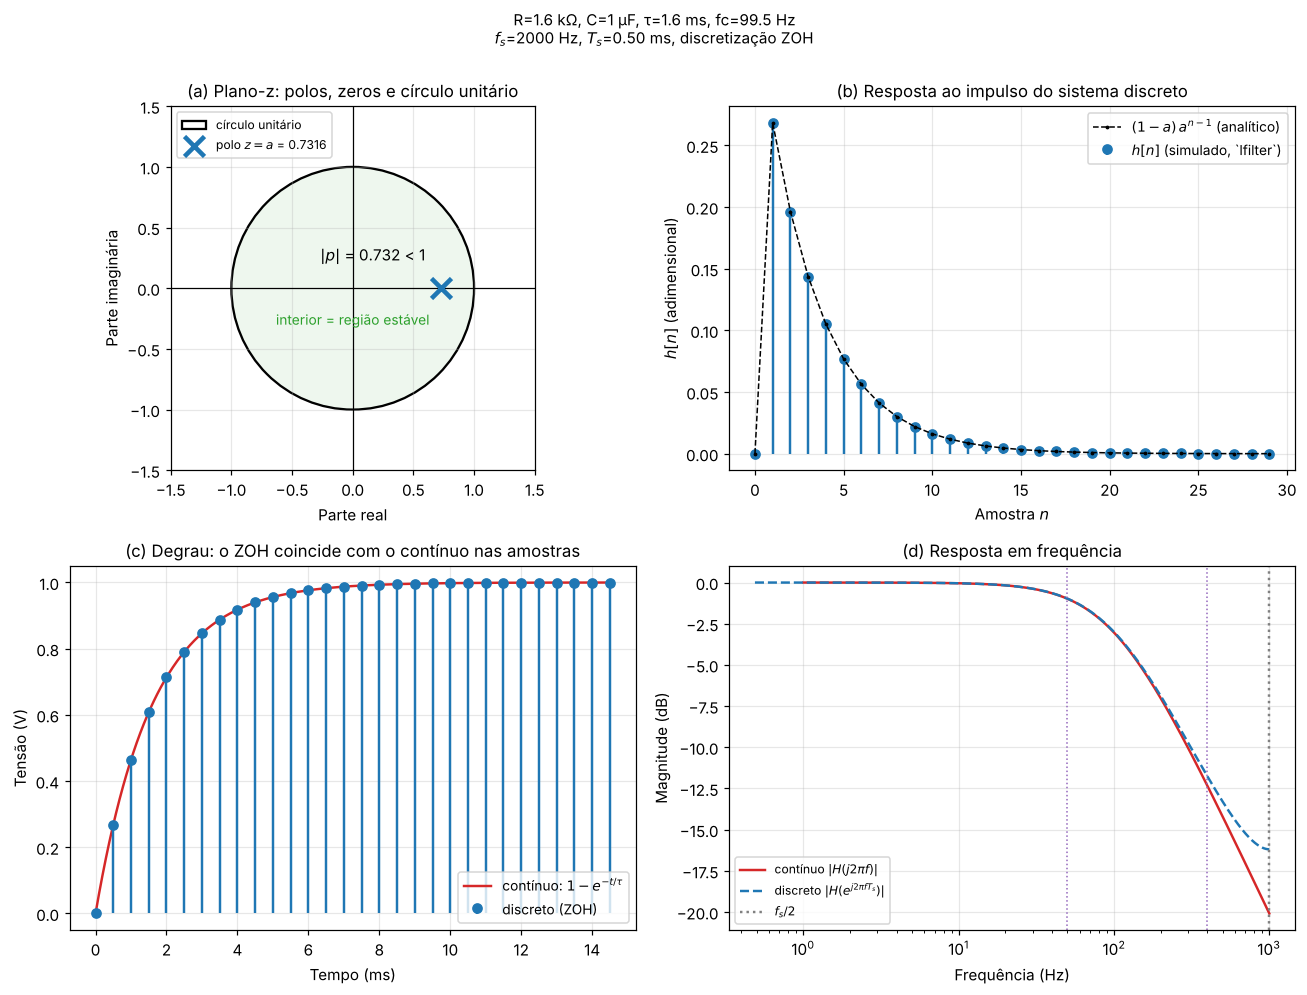

In [17]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9))

# (a) plano-z
ax = axs[0, 0]
ax.add_patch(Circle((0, 0), 1, fill=True, color="tab:green", alpha=.08))
ax.add_patch(Circle((0, 0), 1, fill=False, color="k", lw=1.5, label="círculo unitário"))
ax.axhline(0, color="k", lw=.8); ax.axvline(0, color="k", lw=.8)
ax.plot(p_d.real, p_d.imag, "x", color="tab:blue", ms=13, mew=3, label=f"polo $z=a$ = {p_d[0].real:.4f}")
ax.annotate(f"$|p|$ = {abs(p_d[0]):.3f} < 1", (p_d[0].real, 0), textcoords="offset points", xytext=(-10, 18), ha="right")
ax.text(0, -0.3, "interior = região estável", color="tab:green", ha="center", fontsize=9)
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal")
ax.set_xlabel("Parte real"); ax.set_ylabel("Parte imaginária")
ax.set_title("(a) Plano-z: polos, zeros e círculo unitário"); ax.legend(loc="upper left", fontsize=8)

# (b) resposta ao impulso
ax = axs[0, 1]
ax.stem(n, h_n, linefmt="tab:blue", markerfmt="o", basefmt=" ", label="$h[n]$ (simulado, `lfilter`)")
ax.plot(n, h_an, "k.--", lw=1, ms=3, label=r"$(1-a)\,a^{n-1}$ (analítico)")
ax.set_xlabel("Amostra $n$"); ax.set_ylabel("$h[n]$ (adimensional)")
ax.set_title("(b) Resposta ao impulso do sistema discreto"); ax.legend()

# (c) degrau: discreto × contínuo
ax = axs[1, 0]
tc_ = np.linspace(0, n[-1]*Ts, 600)
ax.plot(tc_*1e3, 1-np.exp(-tc_/tau), color="tab:red", label="contínuo: $1-e^{-t/\\tau}$")
ax.stem(n*Ts*1e3, y_deg_d, linefmt="tab:blue", markerfmt="o", basefmt=" ", label="discreto (ZOH)")
ax.set_xlabel("Tempo (ms)"); ax.set_ylabel("Tensão (V)")
ax.set_title("(c) Degrau: o ZOH coincide com o contínuo nas amostras"); ax.legend(loc="lower right")

# (d) resposta em frequência: contínuo × discreto
ax = axs[1, 1]
wd, hd = signal.freqz(b_d, a_d, worN=2048, fs=fs)
fq = np.linspace(1, fs/2, 2048)
ax.semilogx(fq, 20*np.log10(abs(H_jw(fq))), color="tab:red", label="contínuo $|H(j2\\pi f)|$")
ax.semilogx(wd[1:], 20*np.log10(abs(hd[1:])), "--", color="tab:blue", label="discreto $|H(e^{j2\\pi f T_s})|$")
ax.axvline(fs/2, color="gray", ls=":", label="$f_s/2$")
for fx in (f1, f2): ax.axvline(fx, color="tab:purple", ls=":", lw=1)
ax.set_xlabel("Frequência (Hz)"); ax.set_ylabel("Magnitude (dB)")
ax.set_title("(d) Resposta em frequência"); ax.legend(loc="lower left", fontsize=8)

fig.suptitle(f"{PARAMS_RC}\n$f_s$={fs:.0f} Hz, $T_s$={Ts*1e3:.2f} ms, discretização ZOH", y=1.0, fontsize=10)
fig.tight_layout(); salvar(fig, "12_plano_z_discreto"); plt.show()

**Leitura dos gráficos**
- (a) O polo real em $z\approx0{,}73$ está **dentro** do círculo unitário → estável. Não há zeros finitos.
- (b) $h[n]$ decai geometricamente com razão $a$ (sem oscilar, porque o polo é real positivo). O primeiro valor é $0$ por causa do atraso de uma amostra.
- (c) A resposta ao degrau discreta coincide **exatamente** com a do circuito contínuo nos instantes $nT_s$.
- (d) Em baixas frequências as respostas são praticamente iguais; perto de $f_s/2$ o modelo discreto se afasta do contínuo — é um efeito do **ZOH** (a entrada é mantida constante entre amostras), não um erro de cálculo.

## Etapa 9 – Relação entre os planos

A ligação entre o plano-s e o plano-z é

$$z=e^{sT_s}\quad\Longrightarrow\quad |z|=e^{\sigma T_s},\qquad \angle z=\omega T_s\qquad(s=\sigma+j\omega)$$

Portanto:

| Plano-s | Plano-z |
|---|---|
| $\sigma<0$ (semiplano esquerdo) | $\lvert z\rvert<1$ (**dentro** do círculo unitário) |
| $\sigma=0$ (eixo $j\omega$) | $\lvert z\rvert=1$ (**sobre** o círculo unitário) |
| $\sigma>0$ (semiplano direito) | $\lvert z\rvert>1$ (**fora** do círculo unitário) |

**Aplicação ao RC:** o polo $s_p=-1/\tau=-625$ rad/s vai para $z_p=e^{-T_s/\tau}$, exatamente o polo $a$ do modelo discreto da Etapa 8.

Para ilustrar os três casos, mapeamos também dois polos "de teste" (não fazem parte do RC): um **marginal** ($s=\pm j2\pi\cdot 50$) e um **instável** ($s=+300$ rad/s).

In [18]:
s_rc   = -1/tau                       # polo do RC
z_rc   = np.exp(s_rc*Ts)
print(f"Polo do RC: s = {s_rc:.1f} rad/s  ->  z = e^(s·Ts) = {z_rc:.5f}   (polo de H(z) = {p_d[0].real:.5f})")
assert np.isclose(z_rc, p_d[0].real)

# polos de teste
testes = {
    "RC (estável)":            complex(s_rc, 0),
    "marginal (±j2π·50)":      complex(0, 2*np.pi*50),
    "marginal (conjugado)":    complex(0, -2*np.pi*50),
    "instável (+300 rad/s)":   complex(300, 0),
}
linhas = []
for nome, s_ in testes.items():
    z_ = np.exp(s_*Ts)
    linhas.append({"polo": nome, "s (rad/s)": s_, "Re(s)": s_.real, "|z|": abs(z_),
                   "∠z (°)": np.rad2deg(np.angle(z_)),
                   "estável (s)?": "sim" if s_.real < 0 else ("marginal" if s_.real == 0 else "não"),
                   "estável (z)?": "sim" if abs(z_) < 1-1e-12 else ("marginal" if abs(abs(z_)-1) < 1e-12 else "não")})
display(pd.DataFrame(linhas).set_index("polo").round(4))

Polo do RC: s = -625.0 rad/s  ->  z = e^(s·Ts) = 0.73162   (polo de H(z) = 0.73162)


,s (rad/s),Re(s),|z|,∠z (°),estável (s)?,estável (z)?
polo,,,,,,
RC (estável),-625.0000+ 0.0000j,-625.0,0.7316,0.0,sim,sim
marginal (±j2π·50),0.0000+314.1593j,0.0,1.0000,9.0,marginal,marginal
marginal (conjugado),0.0000-314.1593j,0.0,1.0000,-9.0,marginal,marginal
instável (+300 rad/s),300.0000+ 0.0000j,300.0,1.1618,0.0,não,não


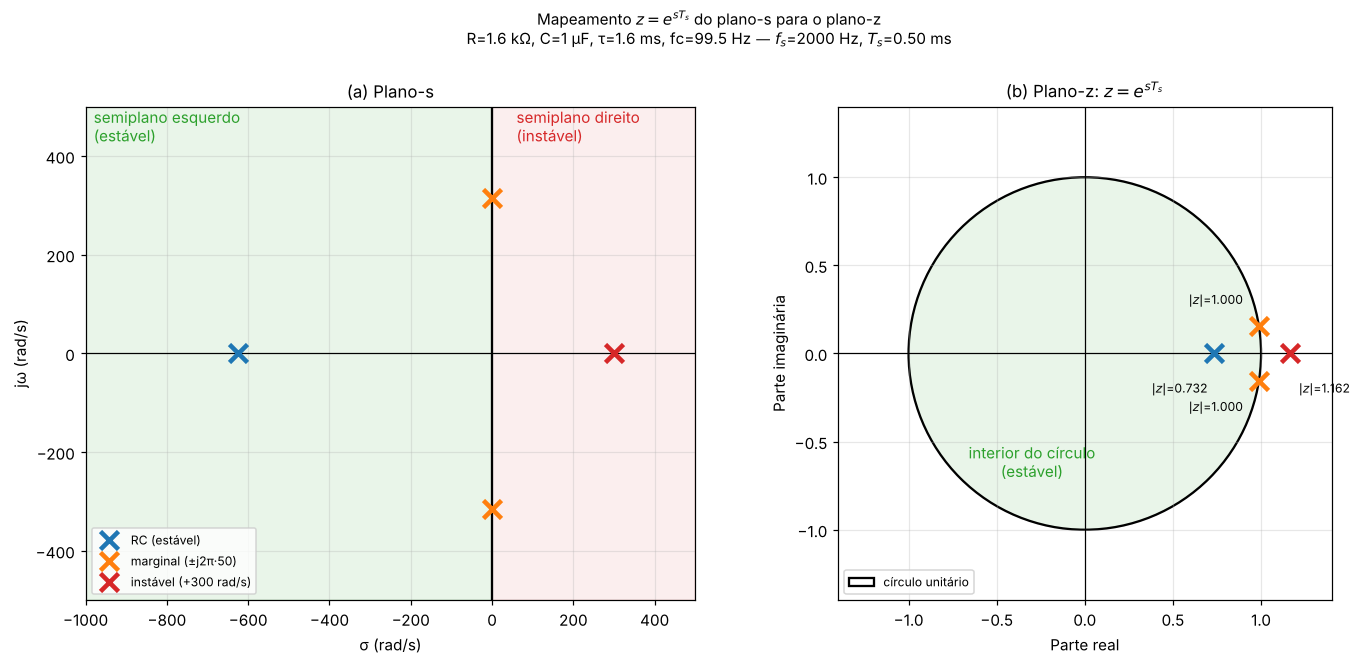

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
cores = {"RC (estável)": "tab:blue", "marginal (±j2π·50)": "tab:orange",
         "marginal (conjugado)": "tab:orange", "instável (+300 rad/s)": "tab:red"}

# (a) plano-s
ax = axs[0]
xl, yl = (-1000, 500), (-500, 500)
ax.axvspan(xl[0], 0, color="tab:green", alpha=.10); ax.axvspan(0, xl[1], color="tab:red", alpha=.08)
ax.axhline(0, color="k", lw=.8); ax.axvline(0, color="k", lw=1.5)
for nome, s_ in testes.items():
    ax.plot(s_.real, s_.imag, "x", color=cores[nome], ms=12, mew=3,
            label=nome if "conjugado" not in nome else None)
ax.text(-980, 430, "semiplano esquerdo\n(estável)", color="tab:green")
ax.text(60, 430, "semiplano direito\n(instável)", color="tab:red")
ax.set_xlim(xl); ax.set_ylim(yl)
ax.set_xlabel("σ (rad/s)"); ax.set_ylabel("jω (rad/s)")
ax.set_title("(a) Plano-s"); ax.legend(loc="lower left", fontsize=8)

# (b) plano-z
OFFS = {"RC (estável)": ((-4, -26), "right"), "marginal (±j2π·50)": ((-10, 14), "right"),
        "marginal (conjugado)": ((-10, -20), "right"), "instável (+300 rad/s)": ((6, -26), "left")}
ax = axs[1]
ax.add_patch(Circle((0, 0), 1, fill=True, color="tab:green", alpha=.10))
ax.add_patch(Circle((0, 0), 1, fill=False, color="k", lw=1.5, label="círculo unitário"))
ax.axhline(0, color="k", lw=.8); ax.axvline(0, color="k", lw=.8)
for nome, s_ in testes.items():
    z_ = np.exp(s_*Ts)
    ax.plot(z_.real, z_.imag, "x", color=cores[nome], ms=12, mew=3)
    off, ha = OFFS[nome]
    ax.annotate(f"$|z|$={abs(z_):.3f}", (z_.real, z_.imag), textcoords="offset points", xytext=off, ha=ha, fontsize=8)
ax.text(-0.3, -0.7, "interior do círculo\n(estável)", color="tab:green", ha="center")
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal")
ax.set_xlabel("Parte real"); ax.set_ylabel("Parte imaginária")
ax.set_title("(b) Plano-z: $z=e^{sT_s}$"); ax.legend(loc="lower left", fontsize=8)

fig.suptitle(f"Mapeamento $z=e^{{sT_s}}$ do plano-s para o plano-z\n{PARAMS_RC} — $f_s$={fs:.0f} Hz, $T_s$={Ts*1e3:.2f} ms", y=1.0, fontsize=10)
fig.tight_layout(); salvar(fig, "13_s_para_z"); plt.show()

### Efeito da frequência de amostragem sobre o polo discreto
Como $z_p=e^{-T_s/\tau}$, quanto **maior** $f_s$, mais o polo discreto se aproxima de $z=1$ (limite do círculo unitário): amostrando muito rápido, o sistema "parece" quase integrador entre uma amostra e outra. Já $|z_p|<1$ **sempre** que $\tau>0$, ou seja, o mapeamento preserva a estabilidade para qualquer $f_s$.

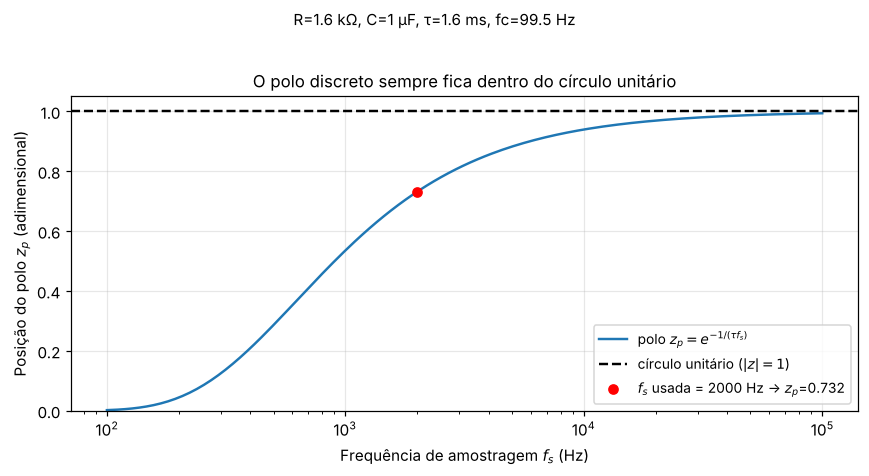

In [20]:
fs_vec = np.logspace(np.log10(100), np.log10(1e5), 200)
z_vec = np.exp(-1/(tau*fs_vec))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.semilogx(fs_vec, z_vec, color="tab:blue", label="polo $z_p=e^{-1/(\\tau f_s)}$")
ax.axhline(1, color="k", ls="--", label="círculo unitário ($|z|=1$)")
ax.plot([fs], [a_exp], "ro", label=f"$f_s$ usada = {fs:.0f} Hz → $z_p$={a_exp:.3f}")
ax.set_xlabel("Frequência de amostragem $f_s$ (Hz)"); ax.set_ylabel("Posição do polo $z_p$ (adimensional)")
ax.set_title("O polo discreto sempre fica dentro do círculo unitário")
ax.set_ylim(0, 1.05); ax.legend(loc="lower right")
fig.suptitle(f"{PARAMS_RC}", y=1.02, fontsize=10)
fig.tight_layout(); salvar(fig, "14_polo_vs_fs"); plt.show()

**Relação entre os critérios de estabilidade**

- **Plano-s:** estável ⇔ todos os polos com $\operatorname{Re}\{s\}<0$ (semiplano esquerdo). A fronteira é o eixo $j\omega$.
- **Plano-z:** estável ⇔ todos os polos com $|z|<1$ (interior do círculo unitário). A fronteira é o círculo $|z|=1$.
- Como $|z|=e^{\sigma T_s}$, as duas condições são **a mesma condição** vista em coordenadas diferentes: $\sigma<0\iff|z|<1$. O eixo $j\omega$ é "enrolado" sobre o círculo unitário.
- O polo do RC ($\sigma=-625$ rad/s) vira $z=0{,}73$: estável nos dois planos.

## Etapa 10 – Discussão

Resumo numérico dos resultados do projeto (gerado automaticamente a partir dos cálculos acima):

In [21]:
resumo = pd.DataFrame({
    "Grandeza": [
        "Constante de tempo τ", "Frequência de corte fc", "Polo contínuo s", "Polo discreto z (ZOH)",
        "Frequência de amostragem fs", "Taxa de Nyquist (2·fmax)", "Resolução espectral Δf (N=2000)",
        "Amplitude medida em 50 Hz", "Amplitude medida em 400 Hz",
        "Frequência aparente com fs=500 Hz", "Frequência aparente com fs=700 Hz",
    ],
    "Valor": [
        f"{tau*1e3:.2f} ms", f"{fc:.2f} Hz", f"{s_rc:.1f} rad/s", f"{a_exp:.4f}",
        f"{fs:.0f} Hz", f"{2*f_max:.0f} Hz", f"{fs/N:.2f} Hz",
        f"{tab_fft.iloc[0]['A medida (V)']:.4f} V", f"{tab_fft.iloc[1]['A medida (V)']:.4f} V",
        f"{f_app(f2, 500):.0f} Hz", f"{f_app(f2, 700):.0f} Hz",
    ],
}).set_index("Grandeza")
display(resumo)
resumo.to_csv(RES_DIR/"resumo_rc.csv")
tab_fft.to_csv(RES_DIR/"espectro_picos_fft.csv")
tab_jan.to_csv(RES_DIR/"metricas_janelas.csv")
print("Tabelas salvas em", RES_DIR.resolve())

,Valor
Grandeza,
Constante de tempo τ,1.60 ms
Frequência de corte fc,99.47 Hz
Polo contínuo s,-625.0 rad/s
Polo discreto z (ZOH),0.7316
Frequência de amostragem fs,2000 Hz
Taxa de Nyquist (2·fmax),800 Hz
Resolução espectral Δf (N=2000),1.00 Hz
Amplitude medida em 50 Hz,0.8935 V
Amplitude medida em 400 Hz,0.2413 V


Tabelas salvas em /home/claude/PDS-Parte-2/resultados


### Respostas às perguntas do roteiro

**1. Quais informações foram identificadas no domínio do tempo?**
A forma de onda de $x(t)$ mostra uma oscilação lenta (50 Hz) com uma ondulação rápida sobreposta (400 Hz), de amplitude menor. Dá para estimar o período da componente dominante e perceber que a saída é mais "suave" que a entrada, mas **não** dá para separar as componentes e medir suas amplitudes com precisão apenas olhando o sinal.

**2. Quais informações ficaram mais evidentes no domínio da frequência?**
A FFT separou claramente as duas componentes: 50 Hz (≈ 0,89 V) e 400 Hz (≈ 0,24 V), além das fases. Ficou evidente o efeito do filtro: a componente de 400 Hz foi atenuada ≈ 3,7× mais que a de 50 Hz.

**3. Como $f_s$ influenciou a análise?**
$f_s$ define a faixa observável ($0$ a $f_s/2$) e a resolução ($\Delta f=f_s/N$). Com $f_s=2000$ Hz (acima de $2f_{max}=800$ Hz) todas as componentes foram observadas corretamente, com $\Delta f=1$ Hz.

**4. O que ocorreu quando Nyquist foi violado?**
Houve **aliasing**: com $f_s=700$ Hz, a componente de 400 Hz apareceu em 300 Hz; com $f_s=500$ Hz, em 100 Hz. A amplitude se manteve, mas a frequência ficou errada, e o espectro não indica que o pico é falso. Matematicamente, $f$ e $f-mf_s$ geram as mesmas amostras.

**5. Qual foi o efeito do janelamento?**
Com número não inteiro de ciclos, a janela retangular causou vazamento espectral alto. Hann e Hamming reduziram os lóbulos laterais (≈ −31 dB e ≈ −42 dB contra ≈ −13 dB), ao custo de um lóbulo principal cerca de 2× mais largo (menor resolução). Hann (e, em menor grau, Hamming) permite enxergar componentes fracas; a retangular separa melhor tons próximos.

**6. Qual a relação entre polos e resposta temporal?**
O polo real $s=-1/\tau$ determina a exponencial $e^{-t/\tau}$ da resposta. Quanto mais à esquerda, mais rápido o decaimento (menor $\tau$). No discreto, o polo $z=a$ real positivo dá $h[n]\propto a^n$, decaimento geométrico sem oscilação; quanto mais próximo de 0, mais rápido, e quanto mais próximo de 1, mais lento.

**7. O sistema contínuo é estável?**
Sim: o único polo, $s=-625$ rad/s, está no semiplano esquerdo.

**8. O sistema discreto é estável?**
Sim: o único polo, $z\approx0{,}73$, tem módulo menor que 1 (dentro do círculo unitário), e $\sum|h[n]|$ é finito.

**9. Como os critérios de estabilidade diferem entre plano-s e plano-z?**
No plano-s a fronteira é o eixo imaginário ($\operatorname{Re}\{s\}<0$); no plano-z é o círculo unitário ($|z|<1$). São a mesma condição vista em coordenadas diferentes.

**10. Como $z=e^{sT_s}$ relaciona os dois sistemas?**
Mapeia cada polo $s$ em $z=e^{sT_s}$: $|z|=e^{\sigma T_s}$ e $\angle z=\omega T_s$. O semiplano esquerdo vira o interior do círculo unitário. No RC, $s=-625\to z=e^{-625\cdot0{,}0005}\approx0{,}73$, que é o polo obtido pela discretização ZOH.

**11. Como esses conceitos podem ser utilizados em Controle e Automação?**
- **Projeto de filtros anti-aliasing** e escolha de $f_s$ em sistemas de aquisição de dados (ex.: sensores industriais, monitoramento de corrente);
- **Análise espectral** (FFT com janelas) para diagnóstico de vibração, harmônicos e ruído em máquinas;
- **Modelagem e discretização** de plantas e filtros (ex.: RC, motores) para implementar controladores digitais em microcontroladores/CLPs;
- **Análise de estabilidade** pelos polos no plano-s e plano-z, garantindo que o controle digital implementado mantenha o comportamento desejado.

## Conclusão

Um único circuito RC permitiu percorrer os quatro domínios: o **tempo** mostrou a forma de onda, a **frequência** revelou suas componentes e os efeitos de amostragem e janelamento, o **plano-s** explicou a dinâmica pelo polo $-1/\tau$ e o **plano-z** mostrou como essa dinâmica é preservada na versão discreta, ligada ao contínuo por $z=e^{sT_s}$.

**Próximos passos possíveis** (opcional): trocar o RC por um RLC (2ª ordem, polos complexos) para ver oscilação no plano-s/z; ativar `NOISE_STD=0.02` para analisar o efeito de ruído no espectro; comparar ZOH com Tustin.